# NB-06 · Stage 7 - Teacher-output caching

**Project:** HiDMamba, hierarchical distillation for 12-lead ECG (PTB-XL, 100 Hz)
**Runtime:** Kaggle, GPU T4, no internet. About 25 to 35 minutes in one session.

## What this stage does
The synopsis (Stage 7): *"With DEAN, Gating, all HODs, and all Professors now frozen, precompute and persist to disk: Professor per-subclass logits, Professor penultimate embeddings, Gating routing distributions g(x), and DEAN's SSM output sequences, for every training-set sample, once."*
The Chief Resident (Stage 8) is then trained against these files only; no teacher is run during its training.

This notebook
1. **re-verifies every frozen teacher** against the files that earlier stages exported (record alignment, deploy files against training checkpoints, fresh forward passes against cached values);
2. **computes the Professor outputs again from the deploy files** (the artefacts that really are downstream) and compares them with the Stage-6 export, so the cache does not rest on an unchecked file;
3. **builds the Gating network** (Stage 4 of the synopsis: a 264,197-parameter MLP on frozen DEAN embeddings, supervised by the superclass labels plus an entropy regulariser) and caches g(x) both **in-sample** and **out-of-fold** (eight patient-disjoint folds);
4. **writes the cache** (`teacher_cache/`) with a manifest, checksums and a small reader (`cache_lib.py`) that Stage 8 imports, and tests the reader (equality with the in-memory arrays, throughput);
5. **measures what the cache contains** that Stage 8 must know: how sharp the in-sample targets are against the out-of-fold ones, how much the teachers agree, what a perfect student of each target blend could reach, where a teacher contradicts a label, and what the DEAN token sequences look like;
6. **draws 16 figures** (300 dpi PNG and vector PDF).

## What is deliberately *not* in the cache
* **Fold 10 (test).** It is never read. Stage 10 evaluates on it exactly once.
* **HOD token sequences.** Stage 8 matches DEAN's sequences (synopsis Stage 8), not the HODs'.
* **Any choice of how the targets are combined.** The cache holds every candidate (Professors, HODs, DEAN in-sample, DEAN out-of-fold, the cascade) and Stage 8 decides; section 10 gives the evidence for that decision.

## The one thing to keep in mind
Professors and HODs were trained on the training records, so their training-set logits are **in-sample** (training AUC about 0.99 to 1.0 against about 0.93 on validation). DEAN and the gate have **out-of-fold** versions. The manifest labels every array `in-sample`, `out-of-fold` or `out-of-sample`, and the notebook quantifies the difference rather than hiding it.

## Inputs (attach these Datasets)
| Dataset | What is read |
|---|---|
| `dean-finetuned-v2` (NB-02) | `dean_finetuned.pt`, `dean_lib.py`, `eval_lib.py`, `split_idx.npz`, `dean_logits_{train,val}.npy`, `dean_logits_train_oof.npy`, `dean_emb_*`, `dean_tokens_*_fp16.npy` |
| `ptbxl-processed-v1` (Stage 1) | `ptbxl_100hz.npy`, `labels_multihot.csv` |
| Stage-5 output (`results-stage-5-hod-distillation`) | `hod_lib.py`, `hods/hod_<n>_deploy.pt`, `hod_logits_{train,val}.npy` |
| Stage-6 output (`professors-v2`) | `prof_lib.py`, `professors/prof_<label>_{final,deploy}.pt`, `prof_logits_*.npy`, `prof_emb_*_fp16.npy` |

## Outputs (`/kaggle/working`, publish as the Dataset `teacher-cache-v1`)
`teacher_cache/` (about 0.9 GB: arrays, `manifest.json`, `cache_lib.py`, `gating_stage7.pt`, `cascade_calibration.json`), `tables/*.csv`, `figures/*.png|pdf`, `stage7_report.json`.


## 0. Environment


In [1]:
import os, sys, glob, json, time, math, copy, random, shutil, warnings, platform, importlib, hashlib, datetime
from collections import defaultdict
from contextlib import nullcontext

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

warnings.filterwarnings('ignore', category=UserWarning)
NB_T0 = time.time()

ON_KAGGLE = os.path.exists('/kaggle/working')
WORK = '/kaggle/working' if ON_KAGGLE else os.path.abspath('./working')
INPUT_ROOT = os.environ.get('NB_INPUT_ROOT', '/kaggle/input')
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
FIG_DIR = os.path.join(WORK, 'figures')
TAB_DIR = os.path.join(WORK, 'tables')
CACHE_DIR = os.path.join(WORK, 'teacher_cache')
for d in (FIG_DIR, TAB_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if ON_KAGGLE:
    assert dev.type == 'cuda', 'No GPU. Settings -> Accelerator -> GPU T4.'
USE_AMP = dev.type == 'cuda'
if USE_AMP:
    torch.backends.cudnn.benchmark = True

def amp():
    return torch.autocast('cuda', dtype=torch.float16) if USE_AMP else nullcontext()

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if USE_AMP: torch.cuda.manual_seed_all(s)

def find_art(name):
    hits = sorted(glob.glob(f'{WORK}/**/{name}', recursive=True)) + sorted(glob.glob(f'{INPUT_ROOT}/**/{name}', recursive=True))
    hits = [h for h in hits if os.path.abspath(CACHE_DIR) not in os.path.abspath(h)]     # never read back the cache that this notebook writes
    return hits[0] if hits else None

def find_one(name):
    p = find_art(name)
    if p is None:
        raise FileNotFoundError(f'{name} not found. Attach the Dataset that contains it (see the list of inputs at the top).')
    return p

def need(*names):
    miss = [n for n in names if n not in globals()]
    if miss:
        raise RuntimeError(f'{miss} not defined. Run the notebook from the top, cell by cell ("Run All"): an earlier cell has not run in this kernel '
                           '(a restarted kernel, a skipped cell, or an earlier error).')

VERSIONS = {'python': platform.python_version(), 'torch': torch.__version__, 'numpy': np.__version__, 'pandas': pd.__version__}
print(VERSIONS)
print('device', dev, '|', torch.cuda.get_device_name(0) if USE_AMP else 'cpu', '| work', WORK)

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'numpy': '2.1.3', 'pandas': '2.3.3'}
device cuda | Tesla T4 | work /kaggle/working


## 1. Configuration


In [2]:
S7 = dict(
    seed=42, min_pos=10, n_boot=300,
    # frozen teachers
    recompute_professors=True,     # recompute all 21 Professors from their deploy files (about 5 min); False reads the Stage-6 export instead
    audit_n=512,                   # records used for the fresh-pass audits
    tol_logit=0.25,                # fp16 against fp16/fp32 comparisons of logits
    tol_fp32=5e-3,                 # fp32 against fp32 (deploy file against training checkpoint)
    # gating network (synopsis Stage 4): 256 -> 512 -> 256 -> 5 = 264,197 parameters
    gate_hidden=(512, 256), gate_dropout=0.1, gate_epochs=80, gate_lr=2e-3, gate_wd=1e-4, gate_bs=256,
    gate_patience=12, gate_warmup=3, gate_lr_floor=0.02, gate_entropy=0.02, gate_oof=True,
    # teacher / label conflicts (diagnostic only)
    conflict_hi=0.9, conflict_lo=0.1,
    # cache
    write_sha256=True, bench_batches=300, bench_bs=64,
    dpi=300,
)
CACHE_VERSION = 'stage7-v1'
print({k: S7[k] for k in ['recompute_professors', 'audit_n', 'gate_hidden', 'gate_epochs', 'gate_entropy', 'gate_oof', 'write_sha256']})

{'recompute_professors': True, 'audit_n': 512, 'gate_hidden': (512, 256), 'gate_epochs': 80, 'gate_entropy': 0.02, 'gate_oof': True, 'write_sha256': True}


## 1b. Libraries


In [3]:
sys.path.insert(0, WORK)
for nm in ('eval_lib.py', 'dean_lib.py', 'hod_lib.py', 'prof_lib.py'):
    src = find_one(nm)
    if os.path.abspath(src) != os.path.join(WORK, nm):
        shutil.copy(src, os.path.join(WORK, nm))
import eval_lib, dean_lib, hod_lib, prof_lib
for m in (eval_lib, dean_lib, hod_lib, prof_lib):
    importlib.reload(m)
from eval_lib import (sigmoid, auc_per_label, f1_at, tune_thresholds, summarize, bootstrap, paired_delta,
                      per_label_table, reliability, fit_calibration, crossfit_ece)
from scipy.stats import spearmanr

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
mpl.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': S7['dpi'], 'font.family': 'serif', 'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
    'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5, 'legend.fontsize': 7.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5, 'legend.frameon': False, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.04, 'axes.linewidth': 0.7, 'figure.constrained_layout.use': True,
})
W1, W2 = 3.5, 7.2                   # single and double column widths in inches
SUPER = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
SUPER_COL = {'NORM': '#009E73', 'MI': '#D55E00', 'STTC': '#0072B2', 'CD': '#CC79A7', 'HYP': '#E69F00'}
SRC_COL = {'Professor': '#0072B2', 'HOD': '#E69F00', 'DEAN': '#333333', 'gate': '#009E73', 'cascade': '#CC79A7', 'mean': '#56B4E9'}
FAMILY = {
    'AMI': 'MI', 'IMI': 'MI', 'LMI': 'MI', 'PMI': 'MI',
    'ISCA': 'STTC', 'ISCI': 'STTC', 'ISC_': 'STTC', 'NST_': 'STTC',
    'CLBBB': 'CD', 'CRBBB': 'CD', 'ILBBB': 'CD', 'IRBBB': 'CD', 'IVCD': 'CD', 'LAFB/LPFB': 'CD', 'WPW': 'CD', '_AVB': 'CD',
    'LAO/LAE': 'HYP', 'LVH': 'HYP', 'RAO/RAE': 'HYP', 'RVH': 'HYP', 'SEHYP': 'HYP'}
FIGLOG = []

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png'))
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'))
    w, h = fig.get_size_inches()
    FIGLOG.append(dict(figure=name, width_in=round(float(w), 2), height_in=round(float(h), 2), dpi=S7['dpi']))
    plt.show()
    plt.close(fig)

print('libraries from', WORK, '| cuda mamba kernels:', dean_lib.USE_CUDA_MAMBA)

libraries from /kaggle/working | cuda mamba kernels: False


## 2. The cache reader
`cache_lib.py` is what Stage 8 imports. It opens the manifest, memory-maps the two large arrays (DEAN's token sequences and the Professor embeddings), keeps the small ones in RAM, and returns aligned batches by record index. It is written here, before the cache, so that the same code that is tested below is the code that ships with the Dataset.


In [4]:
%%writefile cache_lib.py
import json, os, hashlib
import numpy as np
import torch
import torch.nn as nn


class GateMLP(nn.Module):
    """Gating network of the cascade: frozen DEAN embedding (standardised) -> logits over the five superclasses."""

    def __init__(self, d_in=256, hidden=(512, 256), n_out=5, p=0.1):
        super().__init__()
        layers, d = [], d_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(p)]
            d = h
        layers.append(nn.Linear(d, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def load_gate(path, device='cpu'):
    ck = torch.load(path, map_location='cpu', weights_only=False)
    net = GateMLP(ck['d_in'], tuple(ck['hidden']), ck['n_out'], ck['dropout'])
    net.load_state_dict(ck['state'])
    return net.to(device).eval(), ck


class TeacherCache:
    """Read access to the Stage-7 cache of one split ('train' or 'val').

    Arrays larger than `mmap_over_mb` are memory-mapped, the others are loaded. Keys:
    y, idx, prof_logits, prof_emb, hod_logits, cascade_logits, dean_logits_in, dean_logits_oof (train only), dean_logits (val only),
    dean_emb, dean_tokens, gate_logits, gate_logits_oof (train only), conflict.
    """

    def __init__(self, root, split='train', mmap_over_mb=50.0):
        self.root, self.split = root, split
        self.manifest = json.load(open(os.path.join(root, 'manifest.json')))
        self.arrays, self.meta = {}, {}
        for fn, m in self.manifest['files'].items():
            if m['split'] != split:
                continue
            mm = 'r' if m['bytes'] / 1e6 > mmap_over_mb else None
            self.arrays[m['key']] = np.load(os.path.join(root, fn), mmap_mode=mm)
            self.meta[m['key']] = m
        self.n = len(self.arrays['y'])
        for k, a in self.arrays.items():
            assert len(a) == self.n, f'{k}: {len(a)} rows, expected {self.n}'

    def __len__(self):
        return self.n

    def keys(self):
        return sorted(self.arrays)

    def status(self, key):
        return self.meta[key]['sample_status']

    def batch(self, idx, keys=None):
        idx = np.asarray(idx)
        order = np.argsort(idx)                        # sorted reads are much faster on a memory map
        srt = idx[order]
        inv = np.empty_like(order)
        inv[order] = np.arange(len(order))
        out = {}
        for k in (keys or self.keys()):
            out[k] = np.ascontiguousarray(self.arrays[k][srt])[inv]
        return out

    def torch_batch(self, idx, device='cpu', keys=None):
        b = self.batch(idx, keys)
        return {k: torch.from_numpy(v.astype(np.float32) if v.dtype == np.float16 else v).to(device) for k, v in b.items()}


def sha256_file(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def verify(root, deep=False):
    """Returns a list of problems (empty if the cache is intact). deep=True also recomputes the checksums."""
    man = json.load(open(os.path.join(root, 'manifest.json')))
    problems = []
    for fn, m in man['files'].items():
        p = os.path.join(root, fn)
        if not os.path.exists(p):
            problems.append(f'{fn}: missing')
            continue
        a = np.load(p, mmap_mode='r')
        if list(a.shape) != list(m['shape']) or str(a.dtype) != m['dtype']:
            problems.append(f'{fn}: shape/dtype {a.shape}/{a.dtype} differs from the manifest {m["shape"]}/{m["dtype"]}')
        if deep and m.get('sha256') and sha256_file(p) != m['sha256']:
            problems.append(f'{fn}: checksum differs')
    return problems

Overwriting cache_lib.py


## 3. Labels, signals and the cached DEAN outputs
The same loading code as Stage 5 and Stage 6, so that every record index means the same thing in every stage. Training records are folds 1 to 8 (17,418), validation is fold 9 (2,183). **Fold 10 is never read.**


In [5]:
import cache_lib
importlib.reload(cache_lib)

teacher, TCK = hod_lib.load_teacher(find_one('dean_finetuned.pt'), dev)
for p in teacher.parameters():
    p.requires_grad_(False)
LABELS = list(TCK['label_columns'])
ENC_CFG = dict(TCK['enc_config'])
MU = np.array(TCK['norm_mean'], dtype=np.float32)
SD = np.array(TCK['norm_std'], dtype=np.float32)
D_T = ENC_CFG['d_model']
assert LABELS[:5] == SUPER, LABELS[:5]
SUB = LABELS[5:]
assert set(SUB) == set(FAMILY) and len(SUB) == 21, 'the subclass set of the teacher differs from the Professor set'
N_TOK = ENC_CFG['seq_len'] // ENC_CFG['patch']
T_PARAMS = sum(p.numel() for p in teacher.enc.parameters()) + sum(p.numel() for p in teacher.head.parameters())
print(f'teacher: {len(LABELS)} labels | d_model {D_T} | depth {ENC_CFG["depth"]} | {N_TOK} tokens | {T_PARAMS / 1e6:.2f} M parameters')

sig = np.load(find_one('ptbxl_100hz.npy'), mmap_mode='r')
if sig.ndim == 3 and sig.shape[1] != 12 and sig.shape[2] == 12:
    sig = np.transpose(sig, (0, 2, 1))
df = pd.read_csv(find_one('labels_multihot.csv'))
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
assert len(df) == sig.shape[0], f'row mismatch: csv {len(df)} vs npy {sig.shape[0]}'
fold_col = next(c for c in ('strat_fold', 'fold') if c in df.columns)
assert all(c in df.columns for c in LABELS), 'label columns of the csv do not match the teacher'
fold = df[fold_col].values.astype(int)
ecg_col = next((c for c in ('ecg_id', 'ecgid') if c in df.columns), None)
ECG_ID = df[ecg_col].values.astype(np.int64) if ecg_col else np.arange(len(df), dtype=np.int64)

split = np.load(find_one('split_idx.npz'), allow_pickle=True)
tr_idx, va_idx = split['train_idx'], split['val_idx']
assert np.array_equal(tr_idx, np.where(fold <= 8)[0]) and np.array_equal(va_idx, np.where(fold == 9)[0]), 'split_idx.npz disagrees with the fold column'
assert list(split['label_columns']) == LABELS
FOLD_TR = fold[tr_idx]
assert set(np.unique(FOLD_TR)) == set(range(1, 9)) and not (FOLD_TR == 10).any() and not (fold[va_idx] != 9).any()
print('train', len(tr_idx), '| val', len(va_idx), '| fold 10 is never read (', int((fold == 10).sum()), 'records )', '| record ids from', ecg_col or 'row index')

def load_std(idx):
    x = np.nan_to_num(np.ascontiguousarray(sig[idx]).astype(np.float32))
    return (x - MU[None, :, None]) / SD[None, :, None]

Yall = df[LABELS].values.astype(np.float32)
Ytr, Yva = Yall[tr_idx], Yall[va_idx]
N_TR, N_VA = len(tr_idx), len(va_idx)

def ld(name):
    return np.load(find_one(name))

TL_in, TL_va = ld('dean_logits_train.npy'), ld('dean_logits_val.npy')
TL_oof = ld('dean_logits_train_oof.npy')
TE_tr, TE_va = ld('dean_emb_train.npy'), ld('dean_emb_val.npy')
TK_tr, TK_va = ld('dean_tokens_train_fp16.npy'), ld('dean_tokens_val_fp16.npy')
assert TL_in.shape == (N_TR, len(LABELS)) and TL_va.shape == (N_VA, len(LABELS)) and TL_oof.shape == TL_in.shape
assert TK_tr.shape == (N_TR, N_TOK, D_T) and TK_va.shape == (N_VA, N_TOK, D_T) and TK_tr.dtype == np.float16 and TK_va.dtype == np.float16
assert TE_tr.shape == (N_TR, D_T) and TE_va.shape == (N_VA, D_T)
for nm, a in [('TL_in', TL_in), ('TL_va', TL_va), ('TL_oof', TL_oof), ('TE_tr', TE_tr), ('TE_va', TE_va)]:
    assert np.isfinite(a).all(), nm
assert np.isfinite(TK_tr.astype(np.float32)).all() and np.isfinite(TK_va.astype(np.float32)).all()
print('DEAN cache:', TL_in.shape, TK_tr.shape, TE_tr.shape, '| out-of-fold logits: yes')

DATA = dict(X_tr=torch.from_numpy(load_std(tr_idx)).to(dev), X_va=torch.from_numpy(load_std(va_idx)).to(dev))
print('train tensor', tuple(DATA['X_tr'].shape), '| val tensor', tuple(DATA['X_va'].shape), f"| gpu memory {torch.cuda.memory_allocated() / 1e9:.2f} GB" if USE_AMP else '')

HOD_COLS = {}
for s in SUPER:
    si = LABELS.index(s)
    subi = [LABELS.index(l) for l in SUB if FAMILY[l] == s]
    HOD_COLS[s] = dict(sup=[si], sub=subi, cols=[si] + subi)
assert sorted(c for v in HOD_COLS.values() for c in v['cols']) == list(range(len(LABELS))), 'families do not partition the 26 labels'
MP, NB = S7['min_pos'], S7['n_boot']
N_POS_TR, N_POS_VA = Ytr.sum(0), Yva.sum(0)
POS_W = np.clip((N_TR - N_POS_TR) / np.maximum(N_POS_TR, 1), 1.0, 100.0).astype(np.float32)   # the BCE positive weights of Stages 3, 5 and 6
RELIABLE = N_POS_VA >= MP
UNRELIABLE = [l for l, r in zip(LABELS, RELIABLE) if not r]
n_no_super = int((Ytr[:, :5].sum(1) == 0).sum())
print(f'labels with fewer than {MP} validation positives: {UNRELIABLE} | training records without any superclass: {n_no_super}')

@torch.no_grad()
def logits_fp32(net, X, bs=64):
    net.eval()
    return torch.cat([net(X[i:i + bs]).float().cpu() for i in range(0, len(X), bs)]).numpy()

@torch.no_grad()
def predict_net(net, X, bs=256):
    was = net.training
    net.eval()
    lg, em = [], []
    for i in range(0, len(X), bs):
        with amp():
            o, z, t = net(X[i:i + bs], full=True)
        lg.append(o.float().cpu()); em.append(z.float().cpu())
    net.train(was)
    return torch.cat(lg).numpy(), torch.cat(em).numpy()

def predict_prof(net, X, bs=256):
    # fp16 first; if any value overflows the whole set is recomputed in fp32
    lg, em = predict_net(net, X, bs=bs)
    if np.isfinite(lg).all() and np.isfinite(em).all():
        return lg, em
    net.eval(); lg, em = [], []
    with torch.no_grad():
        for i in range(0, len(X), 128):
            o, z, _ = net(X[i:i + 128], full=True)
            lg.append(o.float().cpu()); em.append(z.float().cpu())
    return torch.cat(lg).numpy(), torch.cat(em).numpy()

def macro_auc_cols(Yc, S, min_pos):
    ok = Yc.sum(0) >= min_pos
    if not ok.any():
        ok = Yc.sum(0) >= 1
    a = auc_per_label(Yc, S, 1)
    return float(np.nanmean(a[ok])) if ok.any() else float('nan')

AUDIT = []
def audit(check, value, tol, ok, note=''):
    AUDIT.append(dict(check=check, value=float(value), tolerance=float(tol) if tol is not None else np.nan, passed=bool(ok), note=note))
    print(f"[{'ok' if ok else 'FAIL'}] {check}: {value:.5g}" + (f' (tolerance {tol:g})' if tol is not None else '') + (f' {note}' if note else ''))
    assert ok, f'audit failed: {check}'

teacher: 26 labels | d_model 256 | depth 10 | 40 tokens | 11.49 M parameters
train 17418 | val 2183 | fold 10 is never read ( 2198 records ) | record ids from ecg_id
DEAN cache: (17418, 26) (17418, 40, 256) (17418, 256) | out-of-fold logits: yes
train tensor (17418, 12, 1000) | val tensor (2183, 12, 1000) | gpu memory 0.99 GB
labels with fewer than 10 validation positives: ['PMI', 'ILBBB', 'WPW', 'RVH', 'SEHYP'] | training records without any superclass: 1129


## 4. Audit of the DEAN cache
The two arrays that Stage 8's relational loss needs most, DEAN's token sequences and the out-of-fold logits, were produced in NB-02 and have been used since. Before they are copied into the cache they are checked against a fresh forward pass of the frozen teacher on random training and validation records, and the out-of-fold logits are checked to differ from the in-sample ones in the expected direction.


In [6]:
need('DATA', 'teacher', 'TL_in', 'TK_tr', 'amp')
def use_fast_scan():
    dean_lib.selective_scan = hod_lib.fast_scan

@torch.no_grad()
def teacher_pass(x, bs=128):
    lg, zz, tk = [], [], []
    for i in range(0, len(x), bs):
        with amp():
            o, z, t = teacher.features(x[i:i + bs])
        lg.append(o.float().cpu()); zz.append(z.float().cpu()); tk.append(t.float().cpu())
    return torch.cat(lg).numpy(), torch.cat(zz).numpy(), torch.cat(tk).numpy()

use_fast_scan()
rng = np.random.default_rng(S7['seed'])
DEAN_AUDIT = {}
for nm, X, TLc, TEc, TKc, n in [('train', DATA['X_tr'], TL_in, TE_tr, TK_tr, N_TR), ('val', DATA['X_va'], TL_va, TE_va, TK_va, N_VA)]:
    pick = np.sort(rng.choice(n, min(S7['audit_n'], n), replace=False))
    lg, zz, tk = teacher_pass(X[torch.from_numpy(pick).to(dev)])
    d_lg, d_z, d_tk = np.abs(lg - TLc[pick]), np.abs(zz - TEc[pick]), np.abs(tk - TKc[pick].astype(np.float32))
    DEAN_AUDIT[nm] = dict(logit=d_lg.ravel(), emb=d_z.ravel(), tok=d_tk.ravel())
    audit(f'DEAN {nm}: max |cached logit - fresh logit| on {len(pick)} records', d_lg.max(), S7['tol_logit'], d_lg.max() < S7['tol_logit'])
    audit(f'DEAN {nm}: mean |cached embedding - fresh embedding|', d_z.mean(), 0.01, d_z.mean() < 0.01)
    audit(f'DEAN {nm}: mean |cached token - fresh token|', d_tk.mean(), 0.01, d_tk.mean() < 0.01)

# the out-of-fold logits must be a different, less optimistic version of the in-sample ones
auc_in = macro_auc_cols(Ytr[:, 5:], TL_in[:, 5:], MP)
auc_oof = macro_auc_cols(Ytr[:, 5:], TL_oof[:, 5:], MP)
audit('DEAN out-of-fold differs from in-sample: mean |difference| of the logits', np.abs(TL_oof - TL_in).mean(), None, np.abs(TL_oof - TL_in).mean() > 0.05)
audit('DEAN subclass macro-AUC, in-sample minus out-of-fold (training records)', auc_in - auc_oof, None, auc_in > auc_oof,
      note=f'in-sample {auc_in:.4f}, out-of-fold {auc_oof:.4f}')

[ok] DEAN train: max |cached logit - fresh logit| on 512 records: 0.0039062 (tolerance 0.25)
[ok] DEAN train: mean |cached embedding - fresh embedding|: 5.2403e-05 (tolerance 0.01)
[ok] DEAN train: mean |cached token - fresh token|: 0.00030555 (tolerance 0.01)
[ok] DEAN val: max |cached logit - fresh logit| on 512 records: 0.0039062 (tolerance 0.25)
[ok] DEAN val: mean |cached embedding - fresh embedding|: 5.2729e-05 (tolerance 0.01)
[ok] DEAN val: mean |cached token - fresh token|: 0.00030697 (tolerance 0.01)
[ok] DEAN out-of-fold differs from in-sample: mean |difference| of the logits: 0.57609
[ok] DEAN subclass macro-AUC, in-sample minus out-of-fold (training records): 0.065621 in-sample 0.9878, out-of-fold 0.9222


## 5. The Stage-5 heads
The five HODs are not run again over the whole training set (Stage 5 already did, and exported the committee logits). What is checked here is that the exported file really is what the deploy files produce: every head is rebuilt from its `deploy.pt` and run in fp32 on 128 training and 128 validation records, and compared column by column with the exported logits.


In [7]:
need('DATA', 'HOD_COLS', 'AUDIT', 'logits_fp32')
HOD_TR, HOD_VA = ld('hod_logits_train.npy'), ld('hod_logits_val.npy')
assert HOD_TR.shape == (N_TR, len(LABELS)) and HOD_VA.shape == (N_VA, len(LABELS))
assert np.isfinite(HOD_TR).all() and np.isfinite(HOD_VA).all()
hod_sub_val = macro_auc_cols(Yva[:, 5:], HOD_VA[:, 5:], MP)
audit('HOD committee, subclass columns, validation macro-AUC (sanity)', hod_sub_val, 0.85, hod_sub_val > 0.85)

HOD_DIFF = {}
for n in SUPER:
    ck = torch.load(find_one(f'hod_{n}_deploy.pt'), map_location='cpu', weights_only=False)
    net = hod_lib.HODNet(ck['student_enc_cfg'], ck['config']['depth'], ck['n_sup'], ck['n_sub'], D_T, ck['head_drop'], ck['sub_hidden']).to(dev)
    miss = net.load_state_dict(ck['deploy'], strict=False)
    assert all(k.startswith('proj.') for k in miss.missing_keys) and not miss.unexpected_keys
    cols = HOD_COLS[n]['cols']
    d = []
    for X, ref in [(DATA['X_tr'][:128], HOD_TR), (DATA['X_va'][:128], HOD_VA)]:
        d.append(np.abs(logits_fp32(net, X) - ref[:len(X)][:, cols]))
    d = np.concatenate(d)
    HOD_DIFF[n] = float(d.max())
    audit(f'HOD {n}: max |deploy file (fp32) - exported logits (fp16)| on 256 records', d.max(), S7['tol_logit'], d.max() < S7['tol_logit'], note=f'mean {d.mean():.4f}')
    del net
torch.cuda.empty_cache()

[ok] HOD committee, subclass columns, validation macro-AUC (sanity): 0.93299 (tolerance 0.85)
[ok] HOD NORM: max |deploy file (fp32) - exported logits (fp16)| on 256 records: 0.0025005 (tolerance 0.25) mean 0.0008
[ok] HOD MI: max |deploy file (fp32) - exported logits (fp16)| on 256 records: 0.0034781 (tolerance 0.25) mean 0.0006
[ok] HOD STTC: max |deploy file (fp32) - exported logits (fp16)| on 256 records: 0.0024509 (tolerance 0.25) mean 0.0007
[ok] HOD CD: max |deploy file (fp32) - exported logits (fp16)| on 256 records: 0.0041263 (tolerance 0.25) mean 0.0006
[ok] HOD HYP: max |deploy file (fp32) - exported logits (fp16)| on 256 records: 0.0026207 (tolerance 0.25) mean 0.0010


## 6. The 21 Professors, recomputed from their deploy files
Each Professor is rebuilt from `prof_<label>_deploy.pt` (the file the later stages use), checked against its training checkpoint (`_final.pt`) in fp32, and run over all training and validation records. The result is compared with the arrays that Stage 6 exported. If the two disagree by more than fp16 rounding the notebook stops: a cache built on an export that does not match its models would silently corrupt Stage 8.


In [8]:
need('DATA', 'AUDIT', 'DEAN_AUDIT', 'HOD_DIFF', 'predict_prof')
PROF_LABELS = list(SUB)
FIN_DIFF = {}
lt_l, lv_l, et_l, ev_l = [], [], [], []
t0 = time.time()
S6F = {k: find_art(f) for k, f in dict(lt='prof_logits_train.npy', lv='prof_logits_val.npy', et='prof_emb_train_fp16.npy', ev='prof_emb_val_fp16.npy').items()}
S6 = {k: np.load(p) for k, p in S6F.items()} if all(S6F.values()) else None
if not S7['recompute_professors'] and S6 is None:
    raise FileNotFoundError('recompute_professors is False but the Stage-6 export (prof_logits_*.npy, prof_emb_*_fp16.npy) was not found')
xr = DATA['X_va'][:128]
for k, lab in enumerate(tqdm(PROF_LABELS, desc='Professors')):
    nm = prof_lib.safe_name(lab)
    net, ck = prof_lib.load_professor(find_one(f'prof_{nm}_deploy.pt'), dev)
    assert ck['label'] == lab and ck['parent'] == FAMILY[lab] and ck['col'] == LABELS.index(lab) and ck['d_anchor'] == D_T, (lab, ck['label'], ck['parent'], ck['col'])
    fin = torch.load(find_one(f'prof_{nm}_final.pt'), map_location='cpu', weights_only=False)
    net_f = prof_lib.build_professor(fin['student_enc_cfg'], fin['cfg']['depth'], D_T, fin['cfg']['head_drop']).to(dev)
    net_f.load_state_dict(fin['state'])
    FIN_DIFF[lab] = float(np.abs(logits_fp32(net, xr) - logits_fp32(net_f, xr)).max())
    assert FIN_DIFF[lab] < S7['tol_fp32'], f'{lab}: the deploy file does not reproduce the training checkpoint ({FIN_DIFF[lab]:.2e})'
    if S7['recompute_professors']:
        lt, et = predict_prof(net, DATA['X_tr']); lv, ev = predict_prof(net, DATA['X_va'])
    else:
        lt, et, lv, ev = S6['lt'][:, [k]], S6['et'][:, k].astype(np.float32), S6['lv'][:, [k]], S6['ev'][:, k].astype(np.float32)
    lt_l.append(lt); lv_l.append(lv); et_l.append(et); ev_l.append(ev)
    del net, net_f
    torch.cuda.empty_cache()
P_tr, P_va = np.concatenate(lt_l, 1).astype(np.float32), np.concatenate(lv_l, 1).astype(np.float32)
PE_tr, PE_va = np.stack(et_l, 1).astype(np.float16), np.stack(ev_l, 1).astype(np.float16)
assert P_tr.shape == (N_TR, 21) and P_va.shape == (N_VA, 21) and PE_tr.shape == (N_TR, 21, D_T) and PE_va.shape == (N_VA, 21, D_T)
assert np.isfinite(P_tr).all() and np.isfinite(P_va).all() and np.isfinite(PE_tr.astype(np.float32)).all() and np.isfinite(PE_va.astype(np.float32)).all()
print(f'{len(PROF_LABELS)} Professors, {time.time() - t0:.0f} s')
audit('Professors: max |deploy file - training checkpoint| (fp32, 128 validation records)', max(FIN_DIFF.values()), S7['tol_fp32'], max(FIN_DIFF.values()) < S7['tol_fp32'])

EXP_DIFF = None
if S6 is not None and S7['recompute_professors']:
    d_tr, d_va = np.abs(P_tr - S6['lt']), np.abs(P_va - S6['lv'])
    EXP_DIFF = dict(tr=d_tr.max(0), va=d_va.max(0))
    audit('Professors: max |recomputed logit - Stage-6 export|, training records', d_tr.max(), S7['tol_logit'], d_tr.max() < S7['tol_logit'], note=f'mean {d_tr.mean():.5f}')
    audit('Professors: max |recomputed logit - Stage-6 export|, validation records', d_va.max(), S7['tol_logit'], d_va.max() < S7['tol_logit'], note=f'mean {d_va.mean():.5f}')
    e_tr = np.abs(PE_va.astype(np.float32) - S6['ev'].astype(np.float32)).mean()
    audit('Professors: mean |recomputed embedding - Stage-6 export|, validation records', e_tr, 0.01, e_tr < 0.01)
elif S6 is None:
    print('Stage-6 export not found: the recomputed Professors are used without the comparison')

prof_sub_val = macro_auc_cols(Yva[:, 5:], P_va, MP)
audit('Professors, validation macro-AUC over the reliable subclasses (sanity, Stage 6 reported 0.934)', prof_sub_val, 0.90, prof_sub_val > 0.90)

Professors:   0%|          | 0/21 [00:00<?, ?it/s]

21 Professors, 161 s
[ok] Professors: max |deploy file - training checkpoint| (fp32, 128 validation records): 0 (tolerance 0.005)
[ok] Professors: max |recomputed logit - Stage-6 export|, training records: 0 (tolerance 0.25) mean 0.00000
[ok] Professors: max |recomputed logit - Stage-6 export|, validation records: 0.0039062 (tolerance 0.25) mean 0.00000
[ok] Professors: mean |recomputed embedding - Stage-6 export|, validation records: 2.1529e-06 (tolerance 0.01)
[ok] Professors, validation macro-AUC over the reliable subclasses (sanity, Stage 6 reported 0.934): 0.93378 (tolerance 0.9)


## 7. The Gating network (synopsis Stage 4)
A 264,197-parameter MLP (256 to 512 to 256 to 5) on the frozen, standardised DEAN embedding. Its output `g(x)` is a distribution over the five superclasses (a triage score for "which department should look at this record"); the Chief Resident later mimics it.

* **Target.** The superclass labels, as a distribution: a record with two superclasses puts 0.5 on each; a record without any superclass is left out of the loss (it still gets a `g(x)` at inference).
* **Entropy regulariser.** `L = CE - 0.02·H(g)`: the entropy bonus keeps `g` from collapsing to a hard one-hot router on the in-sample records (a multi-label record is not one-hot).
* **Selection** uses validation fold 9 only; the test fold is not read.
* **Two versions of `g(x)` for every training record.** (1) *In-sample*: the final gate evaluated on the records it was trained on. (2) *Out-of-fold*: for each of the eight training folds a gate trained on the other seven, for the same number of epochs as the final gate and **without** any selection on the held-out fold. The folds are PTB-XL's own patient-disjoint ones, so no patient is in both sides. The OOF version is the honest soft target; the in-sample one is what a literal reading of the synopsis caches. Stage 8 can use either; section 10 shows how different they are.
* The gate was not provided in this project's files, so it is built here to the synopsis specification. If an earlier Stage-4 gate exists, it can be compared with this one through `gate_logits_val.npy`.


In [9]:
need('TE_tr', 'TE_va', 'P_tr', 'HOD_VA', 'AUDIT')
GM, GS = TE_tr.mean(0), TE_tr.std(0) + 1e-6
Xg_tr = ((TE_tr - GM) / GS).astype(np.float32)
Xg_va = ((TE_va - GM) / GS).astype(np.float32)
Yg_tr, Yg_va = Ytr[:, :5], Yva[:, :5]

def gate_targets(Y5):
    n = Y5.sum(1, keepdims=True)
    valid = n[:, 0] > 0
    T = np.where(n > 0, Y5 / np.maximum(n, 1), 0.2)
    return T.astype(np.float32), valid

Tg_tr, Vg_tr = gate_targets(Yg_tr)
Tg_va, Vg_va = gate_targets(Yg_va)

def new_gate():
    return cache_lib.GateMLP(D_T, tuple(S7['gate_hidden']), 5, S7['gate_dropout']).to(dev)

GATE_PARAMS = sum(p.numel() for p in new_gate().parameters())
h1, h2 = S7['gate_hidden']
assert GATE_PARAMS == D_T * h1 + h1 + h1 * h2 + h2 + h2 * 5 + 5, GATE_PARAMS
if D_T == 256:
    assert GATE_PARAMS == 264197, GATE_PARAMS      # the 264K-parameter gate of the synopsis
print(f'gating network: {GATE_PARAMS:,} parameters')

@torch.no_grad()
def gate_logits(net, X, bs=2048):
    net.eval()
    xt = torch.from_numpy(X).to(dev)
    return torch.cat([net(xt[i:i + bs]).float().cpu() for i in range(0, len(xt), bs)]).numpy()

def softmax_np(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def gate_metrics(z, Y5):
    p = softmax_np(z)
    n = Y5.sum(1)
    v = n > 0
    top = p.argmax(1)
    hit = Y5[np.arange(len(Y5)), top] > 0
    single = n == 1
    logp = np.log(np.clip(p, 1e-12, 1.0))
    tgt = np.where(v[:, None], Y5 / np.maximum(n, 1)[:, None], 0.0)
    conf = p.max(1)
    bins = np.minimum((conf[v] * 10).astype(int), 9)
    ece = 0.0
    for b in range(10):
        m = bins == b
        if m.any():
            ece += m.mean() * abs(hit[v][m].mean() - conf[v][m].mean())
    return dict(ce=float(-(tgt * logp).sum(1)[v].mean()), top1=float(hit[v].mean()), top1_single=float(hit[single].mean()) if single.any() else float('nan'),
                entropy=float(-(p * logp).sum(1).mean()), maxp=float(conf.mean()), ece=float(ece))

def train_gate(Xf, T, valid, seed, val=None, stop_at=None):
    set_seed(seed)
    net = new_gate()
    opt = torch.optim.AdamW(net.parameters(), lr=S7['gate_lr'], weight_decay=S7['gate_wd'])
    N, bs = len(Xf), S7['gate_bs']
    spe = int(math.ceil(N / bs))
    total, warm = S7['gate_epochs'] * spe, S7['gate_warmup'] * spe
    Xt, Tt, Vt = torch.from_numpy(Xf).to(dev), torch.from_numpy(T).to(dev), torch.from_numpy(valid.astype(np.float32)).to(dev)
    hist, best, best_ep, best_state, bad, step = [], float('inf'), 0, None, 0, 0
    last = S7['gate_epochs'] if stop_at is None else stop_at
    for ep in range(1, last + 1):
        net.train()
        perm = torch.randperm(N, generator=torch.Generator().manual_seed(seed * 1000 + ep)).to(dev)
        tl, tn = 0.0, 0.0
        for i in range(spe):
            idx = perm[i * bs:(i + 1) * bs]
            for g in opt.param_groups:
                g['lr'] = S7['gate_lr'] * hod_lib.cosine_scale(step, total, warm, S7['gate_lr_floor'])
            logp = F.log_softmax(net(Xt[idx]), 1)
            p = logp.exp()
            ce = -(Tt[idx] * logp).sum(1)
            ent = -(p * logp).sum(1)
            v = Vt[idx]
            loss = ((ce - S7['gate_entropy'] * ent) * v).sum() / v.sum().clamp(min=1.0)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            step += 1
            tl += float(((ce) * v).sum()); tn += float(v.sum())
        row = dict(epoch=ep, train_ce=tl / max(tn, 1.0))
        if val is not None:
            m = gate_metrics(gate_logits(net, val[0]), val[1])
            row.update(val_ce=m['ce'], val_top1=m['top1'], val_entropy=m['entropy'])
            if m['ce'] < best - 1e-4:
                best, best_ep, bad = m['ce'], ep, 0
                best_state = {k: v_.detach().cpu().clone() for k, v_ in net.state_dict().items()}
            else:
                bad += 1
        hist.append(row)
        if val is not None and bad >= S7['gate_patience']:
            break
    if val is not None and best_state is not None:
        net.load_state_dict(best_state)
    return net, hist, (best_ep if val is not None else last)

t0 = time.time()
GATE, GATE_HIST, GATE_BEST = train_gate(Xg_tr, Tg_tr, Vg_tr, S7['seed'], val=(Xg_va, Yg_va))
GZ_tr_in, GZ_va = gate_logits(GATE, Xg_tr), gate_logits(GATE, Xg_va)
print(f'final gate: best epoch {GATE_BEST}/{len(GATE_HIST)} run, {time.time() - t0:.0f} s')
GM_tr_in, GM_va = gate_metrics(GZ_tr_in, Yg_tr), gate_metrics(GZ_va, Yg_va)
print('in-sample (train):', {k: round(v, 4) for k, v in GM_tr_in.items()})
print('validation       :', {k: round(v, 4) for k, v in GM_va.items()})
audit('Gate: validation top-1 routing accuracy (the routed superclass is a true one), sanity', GM_va['top1'], 0.70, GM_va['top1'] > 0.70)

gating network: 264,197 parameters
final gate: best epoch 1/13 run, 5 s
in-sample (train): {'ce': 0.5466, 'top1': 0.8996, 'top1_single': 0.883, 'entropy': 0.6383, 'maxp': 0.7666, 'ece': 0.1261}
validation       : {'ce': 0.7544, 'top1': 0.8343, 'top1_single': 0.81, 'entropy': 0.6552, 'maxp': 0.7591, 'ece': 0.086}
[ok] Gate: validation top-1 routing accuracy (the routed superclass is a true one), sanity: 0.83432 (tolerance 0.7)


In [10]:
need('GZ_tr_in', 'GZ_va', 'GATE_BEST', 'Xg_tr', 'train_gate')
# out-of-fold gate for every training record: eight patient-disjoint folds, the epoch count of the final gate, no selection on the held-out fold
GZ_tr_oof = np.zeros_like(GZ_tr_in)
if S7['gate_oof']:
    t0 = time.time()
    for f in tqdm(range(1, 9), desc='gate OOF folds'):
        m = FOLD_TR == f
        net_f, _, _ = train_gate(Xg_tr[~m], Tg_tr[~m], Vg_tr[~m], S7['seed'] + f, val=None, stop_at=GATE_BEST)
        GZ_tr_oof[m] = gate_logits(net_f, Xg_tr[m])
        del net_f
    GM_tr_oof = gate_metrics(GZ_tr_oof, Yg_tr)
    print(f'out-of-fold gate, {time.time() - t0:.0f} s:', {k: round(v, 4) for k, v in GM_tr_oof.items()})
    audit('Gate: out-of-fold top-1 accuracy is not higher than in-sample (it must be the more honest of the two)', GM_tr_oof['top1'] - GM_tr_in['top1'], None,
          GM_tr_oof['top1'] <= GM_tr_in['top1'] + 0.005)
else:
    GZ_tr_oof = GZ_tr_in.copy()
    GM_tr_oof = GM_tr_in
    print('gate_oof is False: the out-of-fold array is a copy of the in-sample one and is marked as such in the manifest')

# quality of g(x) on the validation fold, against the HOD and DEAN superclass scores
Pg_va = softmax_np(GZ_va)
GB = {'gate g(x)': bootstrap(Yg_va, Pg_va, np.full(5, 0.5), MP, NB, n_super=5),
      'HOD (sigmoid)': bootstrap(Yg_va, sigmoid(HOD_VA[:, :5]), np.full(5, 0.5), MP, NB, n_super=5),
      'DEAN (sigmoid)': bootstrap(Yg_va, sigmoid(TL_va[:, :5]), np.full(5, 0.5), MP, NB, n_super=5)}
GATE_AUC = pd.DataFrame({k: dict(zip(SUPER, auc_per_label(Yg_va, S, 1))) for k, S in
                         [('gate g(x)', Pg_va), ('HOD (sigmoid)', sigmoid(HOD_VA[:, :5])), ('DEAN (sigmoid)', sigmoid(TL_va[:, :5]))]})
GATE_AUC.loc['macro'] = GATE_AUC.mean()
print(GATE_AUC.round(4).to_string())
GATE_SP = [float(spearmanr(GZ_va[:, c], HOD_VA[:, c])[0]) for c in range(5)]
print('Spearman(gate logit, HOD superclass logit), validation:', dict(zip(SUPER, np.round(GATE_SP, 3))))
torch.save({'state': GATE.state_dict(), 'd_in': D_T, 'hidden': list(S7['gate_hidden']), 'n_out': 5, 'dropout': S7['gate_dropout'], 'norm_mean': GM, 'norm_std': GS,
            'best_epoch': GATE_BEST, 'params': GATE_PARAMS, 'config': {k: S7[k] for k in S7 if k.startswith('gate_')}, 'classes': SUPER,
            'val_metrics': GM_va}, os.path.join(CACHE_DIR, 'gating_stage7.pt'))

gate OOF folds:   0%|          | 0/8 [00:00<?, ?it/s]

out-of-fold gate, 1 s: {'ce': 0.5601, 'top1': 0.8951, 'top1_single': 0.8779, 'entropy': 0.5972, 'maxp': 0.7795, 'ece': 0.1088}
[ok] Gate: out-of-fold top-1 accuracy is not higher than in-sample (it must be the more honest of the two): -0.0045429
       gate g(x)  HOD (sigmoid)  DEAN (sigmoid)
NORM      0.9366         0.9400          0.9403
MI        0.9130         0.9297          0.9290
STTC      0.9156         0.9323          0.9295
CD        0.9017         0.9192          0.9125
HYP       0.8803         0.9089          0.9100
macro     0.9094         0.9260          0.9243
Spearman(gate logit, HOD superclass logit), validation: {'NORM': np.float64(0.965), 'MI': np.float64(0.908), 'STTC': np.float64(0.782), 'CD': np.float64(0.765), 'HYP': np.float64(0.893)}


## 8. Writing the cache
Every array is stored for the training split and for the validation split (fold 9, for monitoring the Chief Resident's distillation fidelity). The cascade logits are what the Chief Resident's per-label distillation reads: the superclass columns come from the HODs, the subclass columns from the Professors. The label-conflict flags are a diagnostic only (section 10) and nothing in the cache applies them.

Sample status written into the manifest:
* `in-sample`: the teacher was trained on these records (Professors, HODs, DEAN on the training split, and the final gate).
* `out-of-fold`: produced by a model that never saw the record's fold (DEAN out-of-fold logits, the out-of-fold gate).
* `out-of-sample`: the validation fold, which none of the teachers was fitted on (their epoch selection did use it).


In [11]:
need('P_tr', 'PE_tr', 'HOD_TR', 'GZ_tr_oof', 'GM_va', 'AUDIT')
C_tr = np.concatenate([HOD_TR[:, :5], P_tr], 1).astype(np.float32)
C_va = np.concatenate([HOD_VA[:, :5], P_va], 1).astype(np.float32)
assert C_tr.shape == (N_TR, 26) and C_va.shape == (N_VA, 26)

def conflicts(Y, A, B):
    # a teacher pair contradicts the label: label 1 while both teachers give it less than conflict_lo, or label 0 while both give it more than conflict_hi.
    # Probabilities are prior-corrected (logit minus log pos_weight), because the networks were trained with positive weights.
    sh = np.log(POS_W)[None, :]
    pa, pb = sigmoid((A - sh).astype(np.float64)), sigmoid((B - sh).astype(np.float64))
    pos = Y > 0.5
    c = (pos & (np.maximum(pa, pb) < S7['conflict_lo'])) | (~pos & (np.minimum(pa, pb) > S7['conflict_hi']))
    return c.astype(np.uint8)

CONF_TR, CONF_VA = conflicts(Ytr, C_tr, TL_oof), conflicts(Yva, C_va, TL_va)

ST_TR_IN, ST_OOF, ST_VA = 'in-sample', 'out-of-fold', 'out-of-sample'
SPEC = [  # key, split, array, description, consumer, sample status, source
    ('y', 'train', Ytr, 'multi-hot labels, order = manifest label_order', 'Stage 8 L_supervised', 'ground truth', 'labels_multihot.csv'),
    ('idx', 'train', tr_idx.astype(np.int64), 'row index of every record in ptbxl_100hz.npy', 'Stage 8 data loader', 'ground truth', 'split_idx.npz'),
    ('ecg_id', 'train', ECG_ID[tr_idx], 'PTB-XL ecg_id (or the row index if the csv has no such column)', 'bookkeeping', 'ground truth', 'labels_multihot.csv'),
    ('fold', 'train', FOLD_TR.astype(np.int8), 'PTB-XL stratified fold (1 to 8)', 'Stage 8 (out-of-fold logic), Stage 9', 'ground truth', 'labels_multihot.csv'),
    ('prof_logits', 'train', P_tr, '21 Professor subclass logits (order = sub_order)', 'Stage 8 L_professor_KD', ST_TR_IN, 'Stage 6 deploy files'),
    ('prof_emb', 'train', PE_tr, 'Professor penultimate embeddings (records, 21, 256), fp16', 'Stage 8 consultation module (keys and values)', ST_TR_IN, 'Stage 6 deploy files'),
    ('hod_logits', 'train', HOD_TR.astype(np.float32), 'HOD committee logits, 26 columns', 'Stage 8 superclass distillation', ST_TR_IN, 'Stage 5 export (verified)'),
    ('cascade_logits', 'train', C_tr, '26 columns: HOD superclass logits, Professor subclass logits', 'Stage 8 L_professor_KD (all labels)', ST_TR_IN, 'Stage 5 + Stage 6'),
    ('dean_logits_in', 'train', TL_in.astype(np.float32), 'DEAN logits on its own training records', 'Stage 8 target option', ST_TR_IN, 'NB-02 cache (verified)'),
    ('dean_logits_oof', 'train', TL_oof.astype(np.float32), 'DEAN logits from models that did not see the record fold', 'Stage 8 target option (recommended blend component)', ST_OOF, 'NB-02 cache (verified)'),
    ('dean_emb', 'train', TE_tr.astype(np.float32), 'DEAN pooled embedding (256)', 'gate input, Stage 9 prototype index', ST_TR_IN, 'NB-02 cache (verified)'),
    ('dean_tokens', 'train', TK_tr, "DEAN's SSM output sequence (records, 40, 256), fp16", 'Stage 8 L_RKD', ST_TR_IN, 'NB-02 cache (verified)'),
    ('gate_logits', 'train', GZ_tr_in.astype(np.float32), 'gating logits (softmax gives g(x)), final gate', 'Stage 8 L_gate_mimic', ST_TR_IN, 'this notebook'),
    ('gate_logits_oof', 'train', GZ_tr_oof.astype(np.float32), 'gating logits from the eight patient-disjoint folds' + ('' if S7['gate_oof'] else ' (NOT computed: copy of the in-sample gate)'), 'Stage 8 L_gate_mimic (honest variant)', ST_OOF if S7['gate_oof'] else ST_TR_IN, 'this notebook'),
    ('conflict', 'train', CONF_TR, '1 where Professor/HOD and DEAN-OOF both contradict the label (diagnostic only)', 'diagnostic', 'diagnostic', 'this notebook'),
    ('y', 'val', Yva, 'multi-hot labels', 'Stage 8 validation', 'ground truth', 'labels_multihot.csv'),
    ('idx', 'val', va_idx.astype(np.int64), 'row index of every record in ptbxl_100hz.npy', 'Stage 8 data loader', 'ground truth', 'split_idx.npz'),
    ('ecg_id', 'val', ECG_ID[va_idx], 'PTB-XL ecg_id', 'bookkeeping', 'ground truth', 'labels_multihot.csv'),
    ('fold', 'val', fold[va_idx].astype(np.int8), 'PTB-XL stratified fold (9)', 'bookkeeping', 'ground truth', 'labels_multihot.csv'),
    ('prof_logits', 'val', P_va, '21 Professor subclass logits', 'Stage 8 validation fidelity', ST_VA, 'Stage 6 deploy files'),
    ('prof_emb', 'val', PE_va, 'Professor penultimate embeddings, fp16', 'Stage 8 validation', ST_VA, 'Stage 6 deploy files'),
    ('hod_logits', 'val', HOD_VA.astype(np.float32), 'HOD committee logits, 26 columns', 'Stage 8 validation', ST_VA, 'Stage 5 export (verified)'),
    ('cascade_logits', 'val', C_va, '26 columns: HOD superclass, Professor subclass', 'Stage 8 validation', ST_VA, 'Stage 5 + Stage 6'),
    ('dean_logits', 'val', TL_va.astype(np.float32), 'DEAN logits (out-of-sample)', 'Stage 8 validation', ST_VA, 'NB-02 cache (verified)'),
    ('dean_emb', 'val', TE_va.astype(np.float32), 'DEAN pooled embedding (256)', 'gate input, Stage 9', ST_VA, 'NB-02 cache (verified)'),
    ('dean_tokens', 'val', TK_va, "DEAN's SSM output sequence, fp16", 'Stage 8 validation', ST_VA, 'NB-02 cache (verified)'),
    ('gate_logits', 'val', GZ_va.astype(np.float32), 'gating logits', 'Stage 8 validation', ST_VA, 'this notebook'),
    ('conflict', 'val', CONF_VA, 'label-conflict flags (diagnostic only)', 'diagnostic', 'diagnostic', 'this notebook'),
]
FILES = {}
t0 = time.time()
for key, spl, arr, desc, consumer, status, source in SPEC:
    n_rows = N_TR if spl == 'train' else N_VA
    assert len(arr) == n_rows, (key, spl, len(arr), n_rows)
    assert not np.issubdtype(arr.dtype, np.floating) or np.isfinite(arr.astype(np.float32)).all(), f'{key} {spl} has non-finite values'
    fn = f"{key}_{spl}{'_fp16' if arr.dtype == np.float16 else ''}.npy"
    path = os.path.join(CACHE_DIR, fn)
    np.save(path, np.ascontiguousarray(arr))
    FILES[fn] = dict(key=key, split=spl, shape=list(arr.shape), dtype=str(arr.dtype), bytes=int(os.path.getsize(path)), description=desc, consumer=consumer,
                     sample_status=status, source=source, sha256=cache_lib.sha256_file(path) if S7['write_sha256'] else None)
print(f'{len(FILES)} arrays written in {time.time() - t0:.0f} s, {sum(m["bytes"] for m in FILES.values()) / 1e9:.2f} GB')

CAL = {'columns': LABELS, 'note': 'Platt parameters fitted on validation fold 9 (sigmoid(a * logit + b)); optimistic for F1, honest for calibration only through cross-fitting (see NB-06 figures)'}
for nm, Z in [('cascade', C_va), ('hod', HOD_VA), ('dean', TL_va)]:
    a_, b_ = fit_calibration(Z, Yva, MP)
    CAL[nm] = dict(a=[float(v) for v in a_], b=[float(v) for v in b_])
json.dump(CAL, open(os.path.join(CACHE_DIR, 'cascade_calibration.json'), 'w'), indent=1)

MANIFEST = dict(
    version=CACHE_VERSION, created=datetime.datetime.now().isoformat(timespec='seconds'), versions=VERSIONS,
    label_order=LABELS, super_order=SUPER, sub_order=SUB, family=FAMILY, parent_col={l: LABELS.index(FAMILY[l]) for l in SUB},
    n_train=N_TR, n_val=N_VA, tokens=[N_TOK, D_T], prof_emb=[21, D_T],
    fold_policy='train = PTB-XL folds 1 to 8, val = fold 9, test = fold 10 (never read by this stage)',
    gate=dict(params=GATE_PARAMS, best_epoch=GATE_BEST, oof=bool(S7['gate_oof']), classes=SUPER, input='standardised DEAN embedding', metrics_val=GM_va),
    unreliable_labels=UNRELIABLE, pos_weight=[float(v) for v in POS_W], teacher_params_M=T_PARAMS / 1e6,
    files=FILES, audit=AUDIT,
    notes=['prof_logits, hod_logits, cascade_logits, dean_logits_in, gate_logits are in-sample on the training split: sharper than on new records',
           'dean_logits_oof and gate_logits_oof are out-of-fold (patient-disjoint folds) and are the honest soft targets',
           'combination of the targets is not applied here; see NB-06 section 10 and the target_ceiling table'])
json.dump(MANIFEST, open(os.path.join(CACHE_DIR, 'manifest.json'), 'w'), indent=1, default=float)
shutil.copy(os.path.join(WORK, 'cache_lib.py'), os.path.join(CACHE_DIR, 'cache_lib.py'))
INV_DF = pd.DataFrame([dict(file=fn, key=m['key'], split=m['split'], shape=str(tuple(m['shape'])), dtype=m['dtype'], MB=m['bytes'] / 1e6, status=m['sample_status'],
                            consumer=m['consumer']) for fn, m in FILES.items()])
INV_DF.to_csv(os.path.join(TAB_DIR, 'cache_inventory.csv'), index=False)
print(INV_DF[INV_DF.split == 'train'].drop(columns=['split']).round(2).to_string(index=False))

28 arrays written in 3 s, 0.65 GB
                      file             key            shape   dtype     MB       status                                            consumer
               y_train.npy               y      (17418, 26) float32   1.81 ground truth                                Stage 8 L_supervised
             idx_train.npy             idx         (17418,)   int64   0.14 ground truth                                 Stage 8 data loader
          ecg_id_train.npy          ecg_id         (17418,)   int64   0.14 ground truth                                         bookkeeping
            fold_train.npy            fold         (17418,)    int8   0.02 ground truth                Stage 8 (out-of-fold logic), Stage 9
     prof_logits_train.npy     prof_logits      (17418, 21) float32   1.46    in-sample                              Stage 8 L_professor_KD
   prof_emb_train_fp16.npy        prof_emb (17418, 21, 256) float16 187.28    in-sample       Stage 8 consultation module (key

## 9. Does the cache read back correctly, and fast enough?
The cache is reloaded from disk with the same `cache_lib.py` that Stage 8 imports, and compared with the arrays still in memory: first the manifest (shapes, dtypes, SHA-256), then random batches of every key, then the saved gate. Stage 8 will read hundreds of thousands of random batches, so the read speed is measured too (memory-mapped against in-RAM, warm page cache).


In [12]:
need('FILES', 'SPEC', 'MANIFEST', 'GATE')
problems = cache_lib.verify(CACHE_DIR, deep=S7['write_sha256'])
assert not problems, problems
audit('cache manifest: files with a problem (shape, dtype, checksum)', len(problems), 0, len(problems) == 0)

MEM = {s_: {sp[0]: sp[2] for sp in SPEC if sp[1] == s_} for s_ in ('train', 'val')}
TC = {s: cache_lib.TeacherCache(CACHE_DIR, s) for s in ('train', 'val')}
rng = np.random.default_rng(1)
worst = 0.0
for s, tc in TC.items():
    assert len(tc) == (N_TR if s == 'train' else N_VA)
    idx = rng.choice(len(tc), min(257, len(tc)), replace=False)
    b = tc.batch(idx)
    for k in tc.keys():
        ref = MEM[s][k][idx]
        assert b[k].shape == ref.shape and b[k].dtype == ref.dtype, (s, k, b[k].shape, ref.shape, b[k].dtype, ref.dtype)
        assert np.array_equal(b[k], ref), f'{s}/{k}: the batch read from disk differs from the array in memory'
    tb = tc.torch_batch(idx[:8], dev, keys=['y', 'prof_logits', 'dean_tokens'])
    assert tb['dean_tokens'].dtype == torch.float32 and tuple(tb['dean_tokens'].shape) == (8, N_TOK, D_T)
audit('cache reader: random batches of every key equal the in-memory arrays (train and validation)', 0.0, 0, True)

gnet, gck = cache_lib.load_gate(os.path.join(CACHE_DIR, 'gating_stage7.pt'), dev)
zz = gate_logits(gnet, ((TE_va[:64] - gck['norm_mean']) / gck['norm_std']).astype(np.float32))
d_gate = float(np.abs(zz - GZ_va[:64]).max())
audit('saved gating network reproduces the cached validation logits', d_gate, 1e-4, d_gate < 1e-4)

# throughput: random batches, as a Stage-8 data loader would draw them
nb_, bs_ = S7['bench_batches'], S7['bench_bs']
rng = np.random.default_rng(2)
keys_all = TC['train'].keys()
def time_batches(fn):
    ts = []
    for _ in range(nb_):
        idx = rng.integers(0, N_TR, bs_)
        t = time.perf_counter(); fn(idx); ts.append((time.perf_counter() - t) * 1e3)
    return np.array(ts)
def ram_read(idx):
    return {k: MEM['train'][k][idx] for k in keys_all}
BENCH = {'RAM, all keys': time_batches(ram_read),
         'cache_lib (memory map), all keys': time_batches(lambda i: TC['train'].batch(i)),
         'cache_lib, Stage-8 keys, to GPU': time_batches(lambda i: TC['train'].torch_batch(i, dev, keys=['y', 'cascade_logits', 'prof_emb', 'gate_logits_oof', 'dean_tokens', 'dean_logits_oof']))}
BENCH_DF = pd.DataFrame({k: dict(median_ms=float(np.median(v)), p95_ms=float(np.percentile(v, 95)), batches_per_s=float(1e3 / np.mean(v))) for k, v in BENCH.items()}).T
print(BENCH_DF.round(2).to_string())
steps_per_epoch = N_TR // bs_
print(f'one epoch of {steps_per_epoch} batches of {bs_} reads in about {steps_per_epoch * np.mean(BENCH["cache_lib, Stage-8 keys, to GPU"]) / 1e3:.1f} s')
BENCH_DF.to_csv(os.path.join(TAB_DIR, 'cache_read_benchmark.csv'))

[ok] cache manifest: files with a problem (shape, dtype, checksum): 0 (tolerance 0)
[ok] cache reader: random batches of every key equal the in-memory arrays (train and validation): 0 (tolerance 0)
[ok] saved gating network reproduces the cached validation logits: 1.4305e-06 (tolerance 0.0001)
                                  median_ms  p95_ms  batches_per_s
RAM, all keys                          0.33    0.39        3001.53
cache_lib (memory map), all keys       0.55    0.61        1792.54
cache_lib, Stage-8 keys, to GPU        3.64    3.98         271.98
one epoch of 272 batches of 64 reads in about 1.0 s


## 10. What is in the cache: the facts Stage 8 has to design around
Five measurements, none of which changes the cache. They decide how Stage 8 should combine the targets.

1. **In-sample against out-of-sample sharpness.** The same AUC measured on the records a teacher was trained on and on records it never saw.
2. **Agreement between teachers** (Spearman correlation of their logits, per label, training and validation).
3. **The ceiling of every target blend**: the validation AUC that a student reproducing a target exactly would have. A student cannot do better than its teacher, so this is the upper bound of what Stage 8 can gain from each choice.
4. **Teacher-label conflicts**: records on which both a cascade teacher and DEAN contradict the label.
5. **Geometry**: how different the 21 Professor embeddings are from each other (they will be the keys and values of the consultation module), and what DEAN's token Gram matrices look like (the target of the relational loss).


In [13]:
need('FILES', 'CONF_TR', 'GM_va', 'HOD_VA', 'TL_oof')
MASK = RELIABLE[5:]                       # the 16 reliable subclasses
def macro_masked(Yc, S, mask):
    a = auc_per_label(Yc, S, 1)
    return float(np.nanmean(a[mask]))
sg = lambda z: sigmoid(np.asarray(z, dtype=np.float64))
Ysub_tr, Ysub_va = Ytr[:, 5:], Yva[:, 5:]

# ---- 1. in-sample against out-of-sample
SRC_TR = {'Professor': P_tr, 'HOD': HOD_TR[:, 5:], 'DEAN in-sample': TL_in[:, 5:], 'DEAN out-of-fold': TL_oof[:, 5:]}
SRC_VA = {'Professor': P_va, 'HOD': HOD_VA[:, 5:], 'DEAN': TL_va[:, 5:]}
auc_tr = {k: auc_per_label(Ysub_tr, sg(v), 1) for k, v in SRC_TR.items()}
auc_va = {k: auc_per_label(Ysub_va, sg(v), 1) for k, v in SRC_VA.items()}
GAP = pd.DataFrame({'label': SUB, 'family': [FAMILY[l] for l in SUB], 'n_pos_train': N_POS_TR[5:].astype(int), 'n_pos_val': N_POS_VA[5:].astype(int), 'reliable': MASK,
                    'prof_train': auc_tr['Professor'], 'prof_val': auc_va['Professor'], 'hod_train': auc_tr['HOD'], 'hod_val': auc_va['HOD'],
                    'dean_in_train': auc_tr['DEAN in-sample'], 'dean_oof_train': auc_tr['DEAN out-of-fold'], 'dean_val': auc_va['DEAN']}).set_index('label')
GAP['prof_gap'] = GAP.prof_train - GAP.prof_val
GAP['dean_oof_gap'] = GAP.dean_oof_train - GAP.dean_val
GAP.to_csv(os.path.join(TAB_DIR, 'insample_gap.csv'))
rel = GAP[GAP.reliable]
print(f'macro-AUC over the {int(MASK.sum())} reliable subclasses')
print(pd.DataFrame({'train': [rel.prof_train.mean(), rel.hod_train.mean(), rel.dean_in_train.mean(), rel.dean_oof_train.mean()],
                    'validation': [rel.prof_val.mean(), rel.hod_val.mean(), np.nan, rel.dean_val.mean()]},
                   index=['Professors', 'HODs', 'DEAN in-sample', 'DEAN out-of-fold']).round(4).to_string())
print(f"mean gap, in-sample minus validation: Professors {rel.prof_gap.mean():.4f}, DEAN out-of-fold {rel.dean_oof_gap.mean():.4f}")

# ---- 2. agreement between teachers
def sp(a, b):
    return float(spearmanr(a, b)[0])
rows = []
for k, l in enumerate(SUB):
    rows.append(dict(label=l, family=FAMILY[l],
                     prof_hod_train=sp(P_tr[:, k], HOD_TR[:, 5 + k]), prof_dean_train=sp(P_tr[:, k], TL_oof[:, 5 + k]), hod_dean_train=sp(HOD_TR[:, 5 + k], TL_oof[:, 5 + k]),
                     prof_hod_val=sp(P_va[:, k], HOD_VA[:, 5 + k]), prof_dean_val=sp(P_va[:, k], TL_va[:, 5 + k]), hod_dean_val=sp(HOD_VA[:, 5 + k], TL_va[:, 5 + k])))
AGR = pd.DataFrame(rows).set_index('label')
AGR.to_csv(os.path.join(TAB_DIR, 'teacher_agreement.csv'))
print('mean Spearman between the teachers (all 21 subclasses):')
print(AGR.drop(columns='family').mean().round(3).to_string())

# ---- 3. the ceiling of every target blend (validation, 21 subclass columns, reliable ones averaged)
Pv, Hv, Dv = P_va, HOD_VA[:, 5:], TL_va[:, 5:]
BLENDS = {'Professor': Pv, 'HOD': Hv, 'DEAN': Dv, 'mean(Professor, DEAN)': (Pv + Dv) / 2, 'mean(Professor, HOD)': (Pv + Hv) / 2, 'mean(Professor, HOD, DEAN)': (Pv + Hv + Dv) / 3}
rows, CEIL_BOOT = [], {}
for nm, Z in BLENDS.items():
    bt = bootstrap(Ysub_va, sg(Z), np.full(21, 0.5), MP, NB, n_super=1)
    CEIL_BOOT[nm] = bt
    pdl = paired_delta(Ysub_va, sg(Z), sg(Dv), MP, NB) if nm != 'DEAN' else (0.0, 0.0, 0.0)
    rows.append(dict(target=nm, macro_auc=bt['macro_auc'][0], lo=bt['macro_auc'][1], hi=bt['macro_auc'][2], vs_DEAN=f'{pdl[0]:+.4f} [{pdl[1]:+.4f}, {pdl[2]:+.4f}]'))
CEIL = pd.DataFrame(rows).set_index('target')
print(CEIL.round(4).to_string())
CEIL.to_csv(os.path.join(TAB_DIR, 'target_ceiling.csv'))

alphas = np.linspace(0, 1, 11)
ALPHA = pd.DataFrame({'alpha': alphas,
                      'val_prof_dean': [macro_masked(Ysub_va, sg(a * Pv + (1 - a) * Dv), MASK) for a in alphas],
                      'train_prof_in_dean_oof': [macro_masked(Ysub_tr, sg(a * P_tr + (1 - a) * TL_oof[:, 5:]), MASK) for a in alphas],
                      'val_prof_hod': [macro_masked(Ysub_va, sg(a * Pv + (1 - a) * Hv), MASK) for a in alphas]}).set_index('alpha')
ALPHA.to_csv(os.path.join(TAB_DIR, 'target_blend_alpha.csv'))
print('alpha = share of the Professor logit in a Professor/DEAN blend')
print(ALPHA.round(4).to_string())

# the whole cascade (HOD superclass + Professor subclass columns) against the committee and DEAN, 26 labels
CASC = {nm: bootstrap(Yva, sg(Z), np.full(26, 0.5), MP, NB, n_super=5) for nm, Z in [('cascade', C_va), ('HOD committee', HOD_VA), ('DEAN', TL_va)]}
CASC_D = {nm: paired_delta(Yva, sg(Z), sg(TL_va), MP, NB) for nm, Z in [('cascade', C_va), ('HOD committee', HOD_VA)]}
print({k: f"{v['macro_auc'][0]:.4f} [{v['macro_auc'][1]:.4f}, {v['macro_auc'][2]:.4f}]" for k, v in CASC.items()})
print('paired difference to DEAN:', {k: f'{v[0]:+.4f} [{v[1]:+.4f}, {v[2]:+.4f}]' for k, v in CASC_D.items()})

# ---- 4. teacher-label conflicts
rows = []
for j, l in enumerate(LABELS):
    for spl, Y, CF in [('train', Ytr, CONF_TR), ('val', Yva, CONF_VA)]:
        pos = Y[:, j] > 0.5
        rows.append(dict(label=l, split=spl, positives=int(pos.sum()), positive_conflicts=int(CF[pos, j].sum()), negative_conflicts=int(CF[~pos, j].sum()),
                         frac_pos=float(CF[pos, j].mean()) if pos.any() else np.nan, frac_neg=float(CF[~pos, j].mean())))
CONFL = pd.DataFrame(rows)
CONFL.to_csv(os.path.join(TAB_DIR, 'teacher_label_conflicts.csv'), index=False)
c_tr = CONF_TR.sum(1)
print(f"training records with at least one conflicting label: {(c_tr > 0).mean():.3%} | with 3 or more: {(c_tr >= 3).mean():.3%} | validation: {(CONF_VA.sum(1) > 0).mean():.3%}")
print(CONFL[CONFL.split == 'train'].sort_values('positive_conflicts', ascending=False).head(6)[['label', 'positives', 'positive_conflicts', 'negative_conflicts']].to_string(index=False))

macro-AUC over the 16 reliable subclasses
                   train  validation
Professors        0.9981      0.9338
HODs              0.9848      0.9330
DEAN in-sample    0.9852         NaN
DEAN out-of-fold  0.9287      0.9296
mean gap, in-sample minus validation: Professors 0.0643, DEAN out-of-fold -0.0009
mean Spearman between the teachers (all 21 subclasses):
prof_hod_train     0.823
prof_dean_train    0.805
hod_dean_train     0.758
prof_hod_val       0.807
prof_dean_val      0.652
hod_dean_val       0.656
                            macro_auc      lo      hi                     vs_DEAN
target                                                                           
Professor                      0.9339  0.9255  0.9412  +0.0042 [-0.0011, +0.0088]
HOD                            0.9333  0.9253  0.9407  +0.0036 [-0.0015, +0.0093]
DEAN                           0.9298  0.9215  0.9369  +0.0000 [+0.0000, +0.0000]
mean(Professor, DEAN)          0.9363  0.9291  0.9427  +0.0066 [+0.0041, +0

In [14]:
need('GAP', 'AGR', 'CEIL')
# ---- 5a. geometry of the 21 Professor embeddings (validation records)
E_va = PE_va.astype(np.float32)
CKA = np.eye(21)
for i in range(21):
    for j in range(i + 1, 21):
        CKA[i, j] = CKA[j, i] = hod_lib.linear_cka(E_va[:, i], E_va[:, j])
def part_ratio(E):
    ev = np.clip(np.linalg.eigvalsh(np.cov(E.T)), 0, None)
    return float(ev.sum() ** 2 / (np.square(ev).sum() + 1e-12))
PR = np.array([part_ratio(E_va[:, i]) for i in range(21)])
off = CKA[np.triu_indices(21, 1)]
fam_idx = {f: [i for i, l in enumerate(SUB) if FAMILY[l] == f] for f in SUPER[1:]}
within = np.mean([CKA[np.ix_(ix, ix)][np.triu_indices(len(ix), 1)].mean() for ix in fam_idx.values()])
across = np.mean([CKA[np.ix_(fam_idx[a], fam_idx[b])].mean() for a in fam_idx for b in fam_idx if a < b])
print(f'linear CKA between Professor embeddings: mean {off.mean():.3f} (within a family {within:.3f}, across families {across:.3f}), min {off.min():.3f}')
print(f'participation ratio (effective dimensions of the 256): median {np.median(PR):.1f}, range {PR.min():.1f} to {PR.max():.1f}')
pd.DataFrame(CKA, index=SUB, columns=SUB).to_csv(os.path.join(TAB_DIR, 'professor_embedding_cka.csv'))

# ---- 5b. DEAN token sequences: what the relational loss will ask the Chief Resident to reproduce
rng = np.random.default_rng(3)
sub_t = np.sort(rng.choice(N_TR, min(3000, N_TR), replace=False))
TK_s = torch.from_numpy(TK_tr[sub_t].astype(np.float32))
TOK_NORM = TK_s.norm(dim=2).numpy()                                   # (3000, 40)
GRAM = hod_lib.token_gram(TK_s).numpy()                               # (3000, 40, 40), mean-centred cosine, basis free
GRAM_BY = {s: GRAM[Ytr[sub_t, SUPER.index(s)] > 0].mean(0) for s in SUPER}
GRAM_ALL = GRAM.mean(0)
off_t = ~np.eye(N_TOK, dtype=bool)
print(f'DEAN token Gram: mean off-diagonal cosine {GRAM_ALL[off_t].mean():.3f}, mean |off-diagonal| {np.abs(GRAM_ALL[off_t]).mean():.3f}; '
      f'between-record variability of the Gram (mean std) {GRAM.std(0)[off_t].mean():.3f}')
print(f'token L2 norm: mean {TOK_NORM.mean():.2f}, std over records {TOK_NORM.mean(0).std():.3f} over positions')

linear CKA between Professor embeddings: mean 0.609 (within a family 0.652, across families 0.616), min 0.206
participation ratio (effective dimensions of the 256): median 7.1, range 3.2 to 12.4
DEAN token Gram: mean off-diagonal cosine 0.004, mean |off-diagonal| 0.034; between-record variability of the Gram (mean std) 0.352
token L2 norm: mean 16.72, std over records 0.007 over positions


## 11. Figures
Sixteen figures, each saved as PNG (300 dpi) and as vector PDF. Widths follow a two-column layout (7.2 in for full-width figures). Family colours are the same as in Stages 5 and 6; the teacher is dark grey; Professors blue, HODs orange, the gate green.


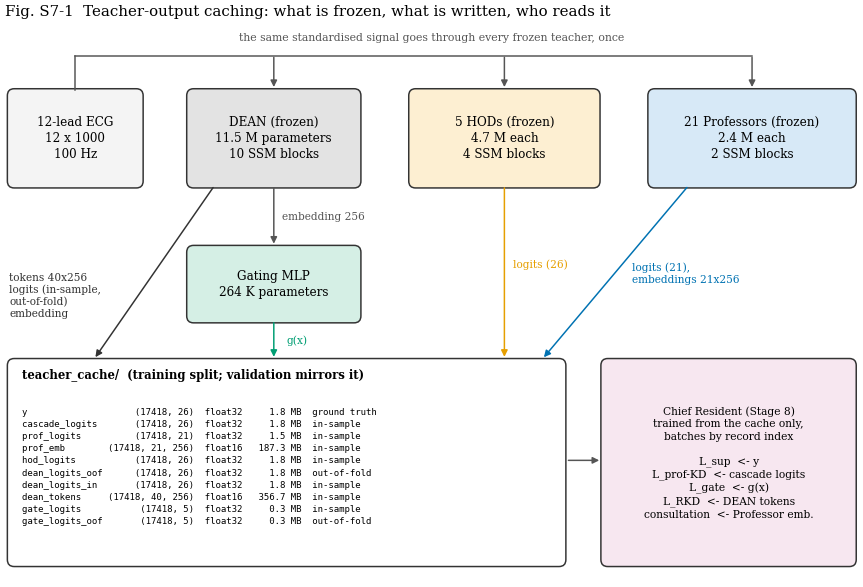

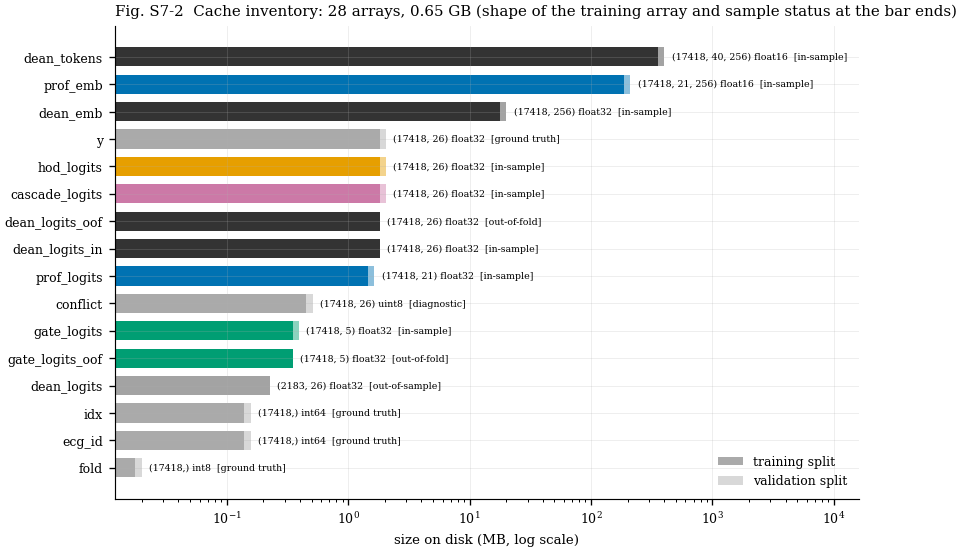

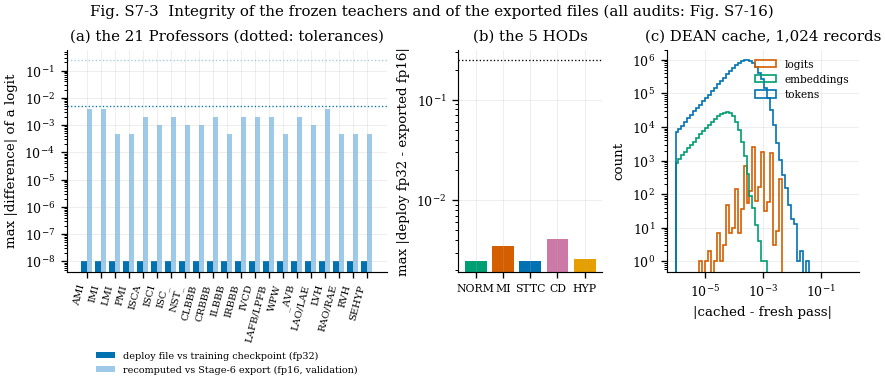

In [15]:
need('INV_DF', 'GATE_HIST', 'AUDIT', 'GAP', 'CKA', 'GRAM_BY', 'BENCH', 'CONFL')
import ast
# Fig. S7-1  data flow
def box(ax, x, y, w, h, text, fc='#FFFFFF', ec='#333333', fs=7.2, lw=0.9, bold=False, mono=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.08', fc=fc, ec=ec, lw=lw))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs, fontweight='bold' if bold else 'normal', linespacing=1.3,
            family='monospace' if mono else None)

def arrow(ax, p0, p1, label=None, color='#555555', rad=0.0, fs=6.3, lxy=None, ha='center', lw=0.9):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle='-|>', mutation_scale=8, lw=lw, color=color, connectionstyle=f'arc3,rad={rad}', shrinkA=1, shrinkB=1))
    if label:
        x, y = lxy if lxy else ((p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2)
        ax.text(x, y, label, fontsize=fs, ha=ha, va='center', color=color, linespacing=1.2)

fig, ax = plt.subplots(figsize=(W2, 4.9))
ax.set_xlim(0, 10); ax.set_ylim(0, 6.4); ax.axis('off'); ax.grid(False)
box(ax, 0.05, 4.55, 1.55, 1.1, '12-lead ECG\n12 x 1000\n100 Hz', fc='#F4F4F4')
box(ax, 2.15, 4.55, 2.0, 1.1, f'DEAN (frozen)\n{T_PARAMS / 1e6:.1f} M parameters\n{ENC_CFG["depth"]} SSM blocks', fc='#E3E3E3', bold=False)
box(ax, 4.75, 4.55, 2.2, 1.1, '5 HODs (frozen)\n4.7 M each\n4 SSM blocks', fc='#FDEFD2')
box(ax, 7.55, 4.55, 2.4, 1.1, '21 Professors (frozen)\n2.4 M each\n2 SSM blocks', fc='#D7E9F7')
box(ax, 2.15, 3.0, 2.0, 0.85, f'Gating MLP\n{GATE_PARAMS / 1e3:.0f} K parameters', fc='#D5EFE5')
ax.plot([0.82, 0.82], [5.65, 6.05], color='#555555', lw=0.9); ax.plot([0.82, 8.75], [6.05, 6.05], color='#555555', lw=0.9)
for xx in (3.15, 5.85, 8.75):
    arrow(ax, (xx, 6.05), (xx, 5.67))
ax.text(5.0, 6.22, 'the same standardised signal goes through every frozen teacher, once', fontsize=6.5, ha='center', color='#555555')
arrow(ax, (3.15, 4.55), (3.15, 3.87), 'embedding 256', lxy=(3.25, 4.2), ha='left')
FT = INV_DF[INV_DF.split == 'train'].set_index('key')
box(ax, 0.05, 0.2, 6.5, 2.35, '', fc='#FFFFFF')
ax.text(0.2, 2.38, 'teacher_cache/  (training split; validation mirrors it)', fontsize=7, fontweight='bold', va='center')
lines = []
for k_ in ['y', 'cascade_logits', 'prof_logits', 'prof_emb', 'hod_logits', 'dean_logits_oof', 'dean_logits_in', 'dean_tokens', 'gate_logits', 'gate_logits_oof']:
    r_ = FT.loc[k_]
    lines.append(f'{k_:16s}{r_["shape"]:>16s} {r_["dtype"]:>8s} {r_["MB"]:7.1f} MB  {r_["status"]}')
ax.text(0.2, 1.33, '\n'.join(lines), fontsize=5.4, family='monospace', va='center', linespacing=1.45)
arrow(ax, (2.45, 4.55), (1.05, 2.57), 'tokens 40x256\nlogits (in-sample,\nout-of-fold)\nembedding', color=SRC_COL['DEAN'], lxy=(0.05, 3.3), ha='left')
arrow(ax, (3.15, 3.0), (3.15, 2.57), 'g(x)', color=SRC_COL['gate'], lxy=(3.3, 2.78), ha='left')
arrow(ax, (5.85, 4.55), (5.85, 2.57), 'logits (26)', color=SRC_COL['HOD'], lxy=(5.95, 3.65), ha='left')
arrow(ax, (8.0, 4.55), (6.3, 2.57), 'logits (21),\nembeddings 21x256', color=SRC_COL['Professor'], lxy=(7.35, 3.55), ha='left')
box(ax, 7.0, 0.2, 2.95, 2.35, 'Chief Resident (Stage 8)\ntrained from the cache only,\nbatches by record index\n\nL_sup  <- y\nL_prof-KD  <- cascade logits\nL_gate  <- g(x)\nL_RKD  <- DEAN tokens\nconsultation  <- Professor emb.', fc='#F7E7F0', fs=6.4)
arrow(ax, (6.58, 1.4), (6.98, 1.4))
ax.set_title('Fig. S7-1  Teacher-output caching: what is frozen, what is written, who reads it', loc='left', fontsize=9)
save_fig(fig, 'figS7_01_dataflow')

# Fig. S7-2  inventory
KEYCOL = {'prof': SRC_COL['Professor'], 'hod': SRC_COL['HOD'], 'cascade': SRC_COL['cascade'], 'dean': SRC_COL['DEAN'], 'gate': SRC_COL['gate']}
def key_color(k):
    for p, c in KEYCOL.items():
        if k.startswith(p):
            return c
    return '#AAAAAA'
agg = INV_DF.groupby(['key', 'split']).MB.sum().unstack(fill_value=0.0)
agg['total'] = agg.sum(1)
agg = agg.sort_values('total')
tr_meta = INV_DF.drop_duplicates('key').set_index('key')
fig, ax = plt.subplots(figsize=(W2, 4.6))
yy = np.arange(len(agg))
ax.barh(yy, agg['train'], color=[key_color(k) for k in agg.index], height=0.7, label='training split')
ax.barh(yy, agg['val'], left=agg['train'], color=[key_color(k) for k in agg.index], alpha=0.45, height=0.7, label='validation split')
for i, (k, r) in enumerate(agg.iterrows()):
    mt = tr_meta.loc[k] if k in tr_meta.index else None
    ax.text(r['total'] * 1.15, i, f"{tuple(int(v) for v in ast.literal_eval(mt['shape']))} {mt['dtype']}  [{mt['status']}]" if mt is not None else '', fontsize=5.6, va='center')
ax.set_yticks(yy); ax.set_yticklabels(agg.index); ax.set_xscale('log'); ax.set_xlim(agg['total'].min() * 0.6, agg['total'].max() * 40)
ax.set_xlabel('size on disk (MB, log scale)'); ax.legend(loc='lower right')
ax.set_title(f'Fig. S7-2  Cache inventory: {len(FILES)} arrays, {INV_DF.MB.sum() / 1e3:.2f} GB (shape of the training array and sample status at the bar ends)', loc='left')
save_fig(fig, 'figS7_02_inventory')

# Fig. S7-3  integrity of the frozen teachers
fig, axes = plt.subplots(1, 3, figsize=(W2, 3.2), gridspec_kw=dict(width_ratios=[2.0, 0.9, 1.2]))
ax = axes[0]
xx = np.arange(21)
ax.bar(xx - 0.2, np.maximum([FIN_DIFF[l] for l in SUB], 1e-8), 0.4, color=SRC_COL['Professor'], label='deploy file vs training checkpoint (fp32)')
if EXP_DIFF is not None:
    ax.bar(xx + 0.2, np.maximum(EXP_DIFF['va'], 1e-8), 0.4, color='#9ECAE9', label='recomputed vs Stage-6 export (fp16, validation)')
ax.axhline(S7['tol_fp32'], color=SRC_COL['Professor'], ls=':', lw=0.8); ax.axhline(S7['tol_logit'], color='#9ECAE9', ls=':', lw=0.8)
ax.set_yscale('log'); ax.set_xticks(xx); ax.set_xticklabels(SUB, rotation=75, ha='right', fontsize=6); ax.set_ylabel('max |difference| of a logit')
ax.legend(fontsize=5.8, loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=1); ax.set_title('(a) the 21 Professors (dotted: tolerances)')
ax = axes[1]
ax.bar(range(5), np.maximum([HOD_DIFF[n] for n in SUPER], 1e-8), color=[SUPER_COL[n] for n in SUPER]); ax.axhline(S7['tol_logit'], color='k', ls=':', lw=0.8)
ax.set_yscale('log'); ax.set_xticks(range(5)); ax.set_xticklabels(SUPER, fontsize=6.5); ax.set_ylabel('max |deploy fp32 - exported fp16|'); ax.set_title('(b) the 5 HODs')
ax = axes[2]
for nm, c in [('logit', '#D55E00'), ('emb', '#009E73'), ('tok', '#0072B2')]:
    v = np.concatenate([DEAN_AUDIT['train'][nm], DEAN_AUDIT['val'][nm]])
    ax.hist(np.maximum(v, 1e-6), bins=np.logspace(-6, 0, 60), histtype='step', color=c, lw=1.1, label={'logit': 'logits', 'emb': 'embeddings', 'tok': 'tokens'}[nm])
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('|cached - fresh pass|'); ax.set_ylabel('count'); ax.legend(fontsize=6.3); ax.set_title('(c) DEAN cache, 1,024 records')
fig.suptitle('Fig. S7-3  Integrity of the frozen teachers and of the exported files (all audits: Fig. S7-16)', fontsize=9)
save_fig(fig, 'figS7_03_integrity')

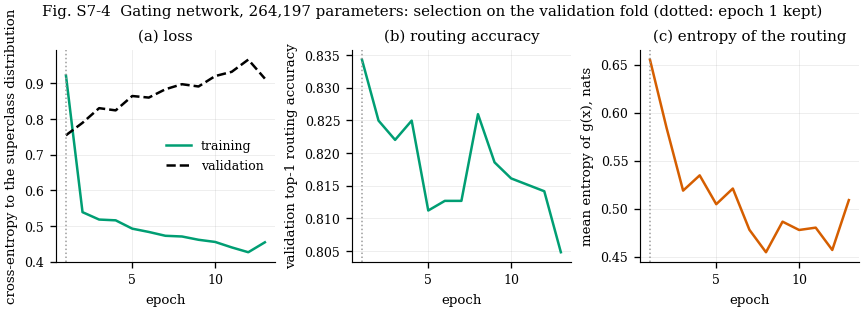

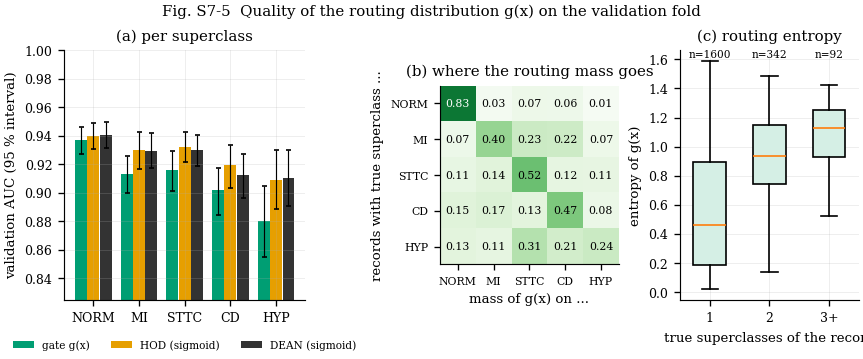

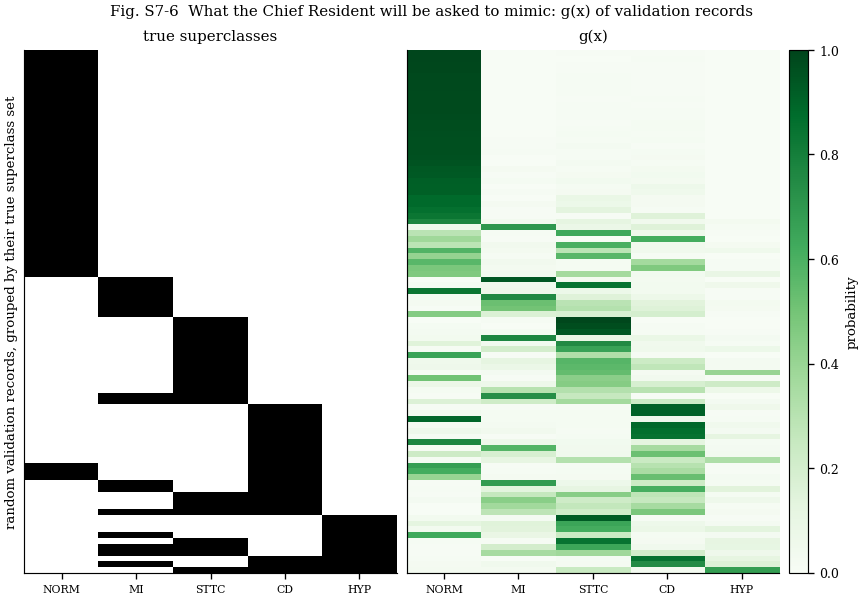

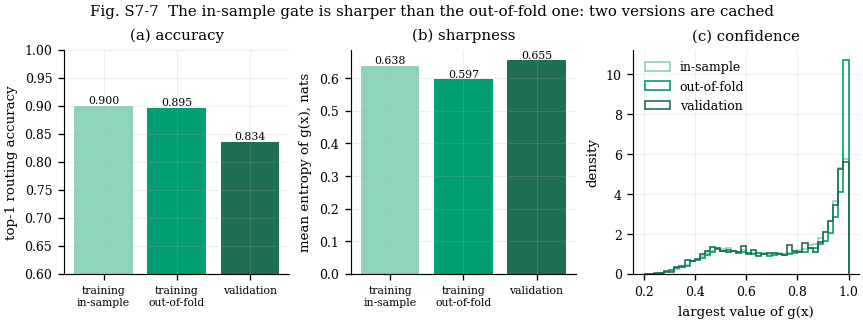

In [16]:
# Fig. S7-4  training of the gate
GH = pd.DataFrame(GATE_HIST)
fig, axes = plt.subplots(1, 3, figsize=(W2, 2.6))
axes[0].plot(GH.epoch, GH.train_ce, color=SRC_COL['gate'], label='training'); axes[0].plot(GH.epoch, GH.val_ce, color='k', ls='--', label='validation')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('cross-entropy to the superclass distribution'); axes[0].legend(); axes[0].set_title('(a) loss')
axes[1].plot(GH.epoch, GH.val_top1, color=SRC_COL['gate']); axes[1].set_xlabel('epoch'); axes[1].set_ylabel('validation top-1 routing accuracy'); axes[1].set_title('(b) routing accuracy')
axes[2].plot(GH.epoch, GH.val_entropy, color='#D55E00'); axes[2].set_xlabel('epoch'); axes[2].set_ylabel('mean entropy of g(x), nats'); axes[2].set_title('(c) entropy of the routing')
for a in axes:
    a.axvline(GATE_BEST, color='#999999', ls=':', lw=0.9)
fig.suptitle(f'Fig. S7-4  Gating network, {GATE_PARAMS:,} parameters: selection on the validation fold (dotted: epoch {GATE_BEST} kept)', fontsize=9)
save_fig(fig, 'figS7_04_gate_training')

# Fig. S7-5  quality of g(x)
fig, axes = plt.subplots(1, 3, figsize=(W2, 3.0), gridspec_kw=dict(width_ratios=[1.35, 1, 1]))
ax = axes[0]
xx = np.arange(5)
for off_, (nm, col) in zip((-0.27, 0, 0.27), [('gate g(x)', SRC_COL['gate']), ('HOD (sigmoid)', SRC_COL['HOD']), ('DEAN (sigmoid)', SRC_COL['DEAN'])]):
    b = GB[nm]
    a_ = GATE_AUC[nm].values[:5]
    ax.bar(xx + off_, a_, 0.26, color=col, label=nm, yerr=[a_ - b['label_auc_lo'], b['label_auc_hi'] - a_], error_kw=dict(lw=0.7, capsize=1.5))
ax.set_xticks(xx); ax.set_xticklabels(SUPER); ax.set_ylim(max(0.5, float(np.nanmin([GB[k]['label_auc_lo'].min() for k in GB])) - 0.03), 1.0); ax.set_ylabel('validation AUC (95 % interval)')
ax.legend(fontsize=6.3, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3); ax.set_title('(a) per superclass')
ax = axes[1]
R = np.array([Pg_va[Yg_va[:, c] > 0].mean(0) for c in range(5)])
im = ax.imshow(R, cmap='Greens', vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{R[i, j]:.2f}', ha='center', va='center', fontsize=6.5, color='white' if R[i, j] > 0.55 else 'black')
ax.set_xticks(range(5)); ax.set_xticklabels(SUPER, fontsize=6.5); ax.set_yticks(range(5)); ax.set_yticklabels(SUPER, fontsize=6.5); ax.grid(False)
ax.set_xlabel('mass of g(x) on ...'); ax.set_ylabel('records with true superclass ...'); ax.set_title('(b) where the routing mass goes')
ax = axes[2]
nt = Yg_va.sum(1)
H = -(Pg_va * np.log(np.clip(Pg_va, 1e-12, 1))).sum(1)
groups = [H[nt == 1], H[nt == 2], H[nt >= 3]]
bp = ax.boxplot(groups, patch_artist=True, showfliers=False, widths=0.55)
ax.set_xticklabels(['1', '2', '3+'])
for p_ in bp['boxes']:
    p_.set_facecolor('#D5EFE5')
ax.set_xlabel('true superclasses of the record'); ax.set_ylabel('entropy of g(x)'); ax.set_title('(c) routing entropy')
for i, g_ in enumerate(groups):
    ax.text(i + 1, ax.get_ylim()[1] * 0.97, f'n={len(g_)}', ha='center', fontsize=6.3)
fig.suptitle('Fig. S7-5  Quality of the routing distribution g(x) on the validation fold', fontsize=9)
save_fig(fig, 'figS7_05_gate_quality')

# Fig. S7-6  g(x) of 90 validation records next to their labels
rng = np.random.default_rng(5)
cand = np.where(Yg_va.sum(1) > 0)[0]
pick = np.sort(rng.choice(cand, min(90, len(cand)), replace=False))
code = (Yg_va[pick] * (2 ** np.arange(5))).sum(1)
pick = pick[np.lexsort((-Pg_va[pick].max(1), code))]
fig, axes = plt.subplots(1, 3, figsize=(W2, 5.0), gridspec_kw=dict(width_ratios=[1, 1, 0.05]))
axes[0].imshow(Yg_va[pick], aspect='auto', cmap='Greys', vmin=0, vmax=1, interpolation='nearest')
im = axes[1].imshow(Pg_va[pick], aspect='auto', cmap='Greens', vmin=0, vmax=1, interpolation='nearest')
for a, t in zip(axes[:2], ['true superclasses', 'g(x)']):
    a.set_xticks(range(5)); a.set_xticklabels(SUPER, fontsize=6.5); a.set_yticks([]); a.set_title(t); a.grid(False)
axes[0].set_ylabel('random validation records, grouped by their true superclass set')
plt.colorbar(im, cax=axes[2]); axes[2].set_ylabel('probability'); axes[2].grid(False)
fig.suptitle('Fig. S7-6  What the Chief Resident will be asked to mimic: g(x) of validation records', fontsize=9)
save_fig(fig, 'figS7_06_gate_examples')

# Fig. S7-7  the gate in-sample, out-of-fold and on the validation fold
P_in, P_oof = softmax_np(GZ_tr_in), softmax_np(GZ_tr_oof)
fig, axes = plt.subplots(1, 3, figsize=(W2, 2.7))
names = ['training\nin-sample', 'training\nout-of-fold', 'validation']
cols_ = ['#8FD3B9', SRC_COL['gate'], '#1F6E55']
mets = [GM_tr_in, GM_tr_oof, GM_va]
axes[0].bar(range(3), [m['top1'] for m in mets], color=cols_); axes[0].set_ylim(0.6, 1.0); axes[0].set_ylabel('top-1 routing accuracy'); axes[0].set_title('(a) accuracy')
for i, m in enumerate(mets):
    axes[0].text(i, m['top1'] + 0.005, f"{m['top1']:.3f}", ha='center', fontsize=6.5)
axes[1].bar(range(3), [m['entropy'] for m in mets], color=cols_); axes[1].set_ylabel('mean entropy of g(x), nats'); axes[1].set_title('(b) sharpness')
for i, m in enumerate(mets):
    axes[1].text(i, m['entropy'] * 1.01, f"{m['entropy']:.3f}", ha='center', fontsize=6.5)
for a in axes[:2]:
    a.set_xticks(range(3)); a.set_xticklabels(names, fontsize=6.5)
for P_, nm, c in [(P_in, 'in-sample', cols_[0]), (P_oof, 'out-of-fold', cols_[1]), (Pg_va, 'validation', cols_[2])]:
    axes[2].hist(P_.max(1), bins=np.linspace(0.2, 1, 41), histtype='step', density=True, color=c, lw=1.2, label=nm)
axes[2].set_xlabel('largest value of g(x)'); axes[2].set_ylabel('density'); axes[2].legend(); axes[2].set_title('(c) confidence')
fig.suptitle('Fig. S7-7  The in-sample gate is sharper than the out-of-fold one: two versions are cached', fontsize=9)
save_fig(fig, 'figS7_07_gate_insample_vs_oof')

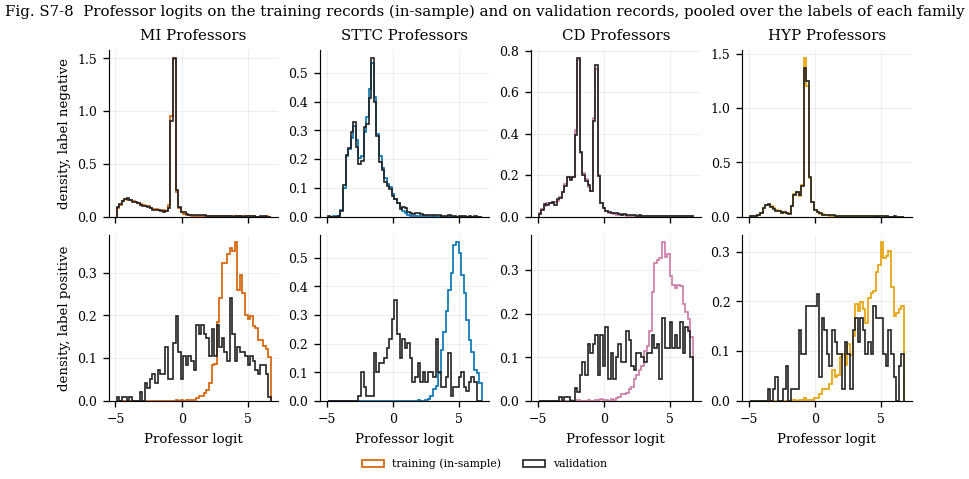

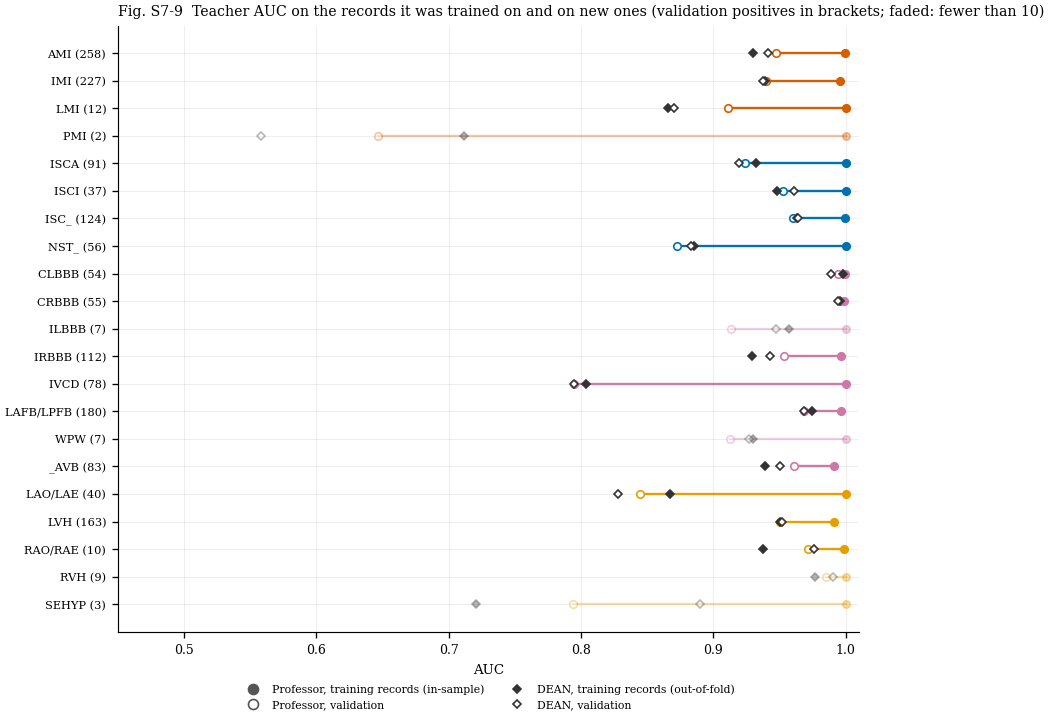

In [17]:
# Fig. S7-8  Professor logits, training against validation, by family
fam_cols = {f: [5 + SUB.index(l) for l in SUB if FAMILY[l] == f] for f in SUPER[1:]}
lo, hi = np.percentile(np.concatenate([P_tr.ravel(), P_va.ravel()]), [0.3, 99.7])
bins_ = np.linspace(lo, hi, 61)
fig, axes = plt.subplots(2, 4, figsize=(W2, 4.0), sharex=True)
for c_, f in enumerate(SUPER[1:]):
    ks = [SUB.index(LABELS[j]) for j in fam_cols[f]]
    for r_, (val_, ttl) in enumerate([(0, 'label negative'), (1, 'label positive')]):
        ax = axes[r_, c_]
        for P_, Y_, ls_, nm, col in [(P_tr, Ytr, '-', 'training (in-sample)', SUPER_COL[f]), (P_va, Yva, '--', 'validation', '#222222')]:
            v = np.concatenate([P_[(Y_[:, 5 + k] > 0.5) == bool(val_), k] for k in ks])
            ax.hist(v, bins=bins_, histtype='step', density=True, color=col, ls=ls_, lw=1.1, label=nm)
        if r_ == 0:
            ax.set_title(f'{f} Professors')
        if c_ == 0:
            ax.set_ylabel(f'density, {ttl}')
        if r_ == 1:
            ax.set_xlabel('Professor logit')
h_, l_ = axes[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc='outside lower center', ncol=2, fontsize=6.5)
fig.suptitle('Fig. S7-8  Professor logits on the training records (in-sample) and on validation records, pooled over the labels of each family', fontsize=9)
save_fig(fig, 'figS7_08_professor_logit_distributions')

# Fig. S7-9  in-sample gap, label by label
order9 = [l for f in SUPER[1:] for l in SUB if FAMILY[l] == f]
fig, ax = plt.subplots(figsize=(W2, 6.0))
for i, l in enumerate(order9[::-1]):
    r_ = GAP.loc[l]
    c = SUPER_COL[FAMILY[l]]
    al = 1.0 if r_.reliable else 0.35
    ax.plot([r_.prof_val, r_.prof_train], [i, i], color=c, lw=1.4, alpha=al)
    ax.plot(r_.prof_train, i, 'o', color=c, ms=4.5, alpha=al)
    ax.plot(r_.prof_val, i, 'o', mfc='white', mec=c, ms=4.5, alpha=al)
    ax.plot(r_.dean_oof_train, i, 'D', color='#333333', ms=3, alpha=al)
    ax.plot(r_.dean_val, i, 'D', mfc='white', mec='#333333', ms=3, alpha=al)
ax.set_yticks(range(len(order9))); ax.set_yticklabels([f'{l} ({int(GAP.loc[l, "n_pos_val"])})' for l in order9[::-1]], fontsize=6.8)
ax.set_xlabel('AUC'); ax.set_xlim(0.45, 1.01)
ax.plot([], [], 'o', color='#555', label='Professor, training records (in-sample)'); ax.plot([], [], 'o', mfc='white', mec='#555', label='Professor, validation')
ax.plot([], [], 'D', color='#333333', ms=3, label='DEAN, training records (out-of-fold)'); ax.plot([], [], 'D', mfc='white', mec='#333333', ms=3, label='DEAN, validation')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=6.5)
ax.set_title(f'Fig. S7-9  Teacher AUC on the records it was trained on and on new ones (validation positives in brackets; faded: fewer than {MP})', loc='left', fontsize=8.5)
save_fig(fig, 'figS7_09_insample_gap')

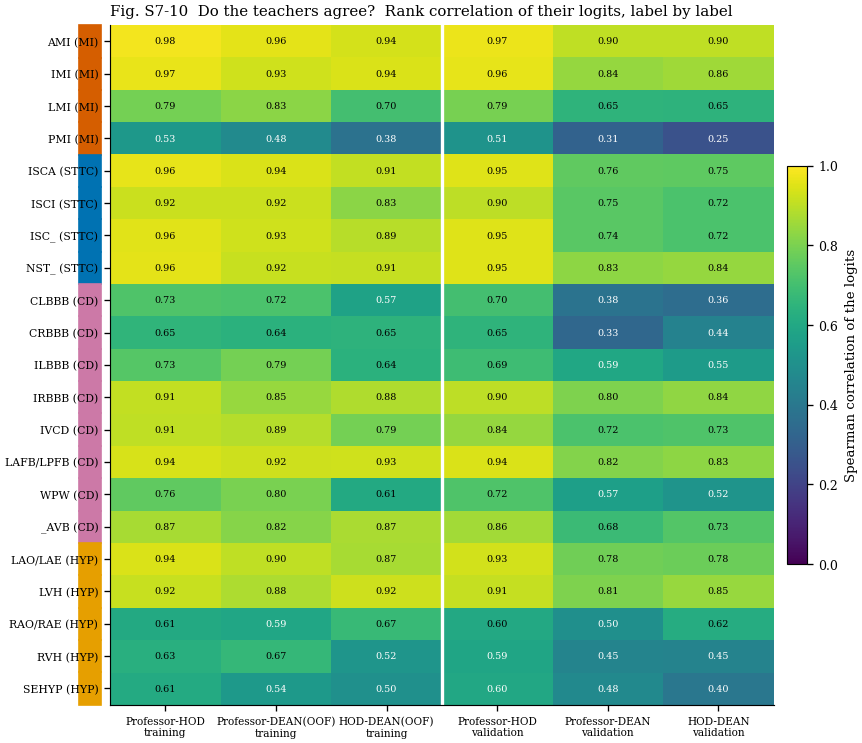

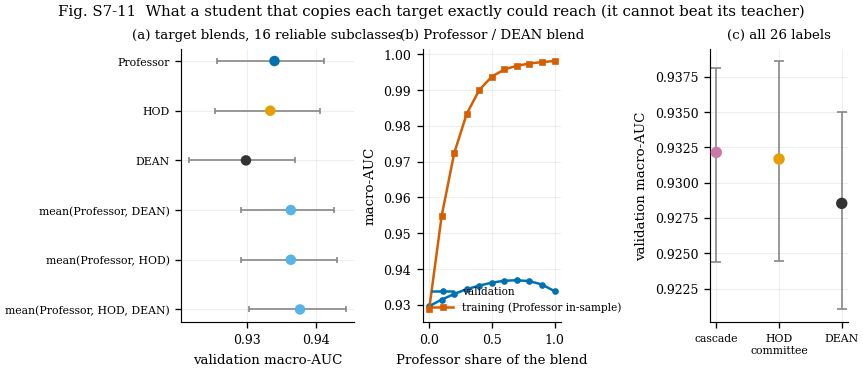

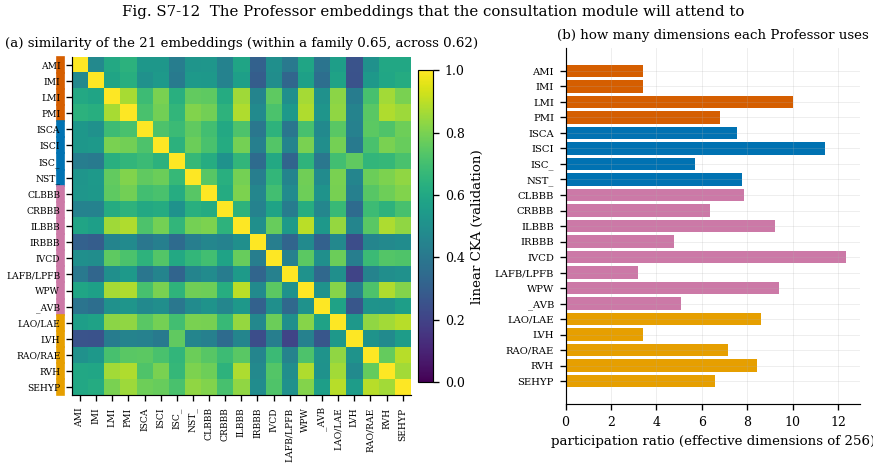

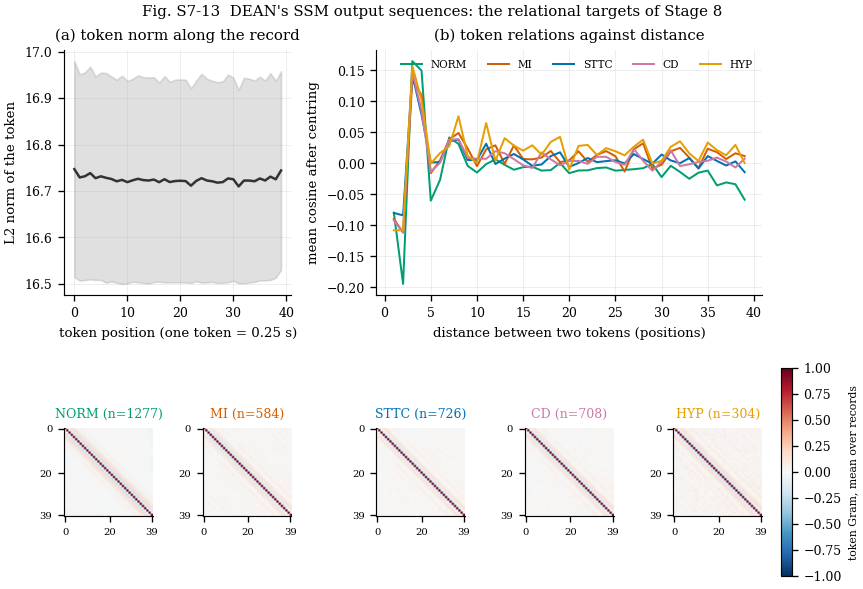

In [18]:
# Fig. S7-10  agreement between the teachers
cols10 = [('prof_hod_train', 'Professor-HOD\ntraining'), ('prof_dean_train', 'Professor-DEAN(OOF)\ntraining'), ('hod_dean_train', 'HOD-DEAN(OOF)\ntraining'),
          ('prof_hod_val', 'Professor-HOD\nvalidation'), ('prof_dean_val', 'Professor-DEAN\nvalidation'), ('hod_dean_val', 'HOD-DEAN\nvalidation')]
M10 = AGR.loc[order9, [c for c, _ in cols10]].values
fig, ax = plt.subplots(figsize=(W2, 6.2))
im = ax.imshow(M10, cmap='viridis', vmin=min(0.0, float(np.nanmin(M10))), vmax=1, aspect='auto')
for i in range(M10.shape[0]):
    for j in range(M10.shape[1]):
        ax.text(j, i, f'{M10[i, j]:.2f}', ha='center', va='center', fontsize=5.8, color='white' if M10[i, j] < 0.6 else 'black')
ax.set_xticks(range(len(cols10))); ax.set_xticklabels([t for _, t in cols10], fontsize=6.3)
ax.set_yticks(range(len(order9))); ax.set_yticklabels([f'{l} ({FAMILY[l]})' for l in order9], fontsize=6.5); ax.grid(False)
ax.axvline(2.5, color='white', lw=2)
for i, l in enumerate(order9):
    ax.add_patch(Rectangle((-0.78, i - 0.5), 0.2, 1, color=SUPER_COL[FAMILY[l]], clip_on=False))
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); cb.set_label('Spearman correlation of the logits')
ax.set_title('Fig. S7-10  Do the teachers agree?  Rank correlation of their logits, label by label', loc='left', fontsize=9)
save_fig(fig, 'figS7_10_teacher_agreement')

# Fig. S7-11  the ceiling of each target
fig, axes = plt.subplots(1, 3, figsize=(W2, 3.1), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
ax = axes[0]
yy = np.arange(len(CEIL))[::-1]
cols_c = [SRC_COL['Professor'], SRC_COL['HOD'], SRC_COL['DEAN'], SRC_COL['mean'], SRC_COL['mean'], SRC_COL['mean']]
ax.errorbar(CEIL.macro_auc, yy, xerr=[CEIL.macro_auc - CEIL.lo, CEIL.hi - CEIL.macro_auc], fmt='none', ecolor='#888888', capsize=2, lw=1)
ax.scatter(CEIL.macro_auc, yy, c=cols_c, s=28, zorder=3)
ax.set_yticks(yy); ax.set_yticklabels(CEIL.index, fontsize=6.5); ax.set_xlabel('validation macro-AUC'); ax.set_title(f'(a) target blends, {int(MASK.sum())} reliable subclasses', fontsize=8)
ax = axes[1]
ax.plot(ALPHA.index, ALPHA.val_prof_dean, 'o-', ms=3, color=SRC_COL['Professor'], label='validation')
ax.plot(ALPHA.index, ALPHA.train_prof_in_dean_oof, 's-', ms=3, color='#D55E00', label='training (Professor in-sample)')
ax.set_xlabel('Professor share of the blend'); ax.set_ylabel('macro-AUC'); ax.legend(fontsize=6.3, loc='lower left'); ax.set_title('(b) Professor / DEAN blend', fontsize=8)
ax = axes[2]
nm_ = ['cascade', 'HOD committee', 'DEAN']
mv = [CASC[k]['macro_auc'] for k in nm_]
ax.errorbar(range(3), [m[0] for m in mv], yerr=[[m[0] - m[1] for m in mv], [m[2] - m[0] for m in mv]], fmt='none', ecolor='#888888', capsize=3, lw=1)
ax.scatter(range(3), [m[0] for m in mv], c=[SRC_COL['cascade'], SRC_COL['HOD'], SRC_COL['DEAN']], s=34, zorder=3)
ax.set_xticks(range(3)); ax.set_xticklabels(['cascade', 'HOD\ncommittee', 'DEAN'], fontsize=6.5); ax.set_ylabel('validation macro-AUC'); ax.set_title('(c) all 26 labels', fontsize=8)
fig.suptitle('Fig. S7-11  What a student that copies each target exactly could reach (it cannot beat its teacher)', fontsize=9)
save_fig(fig, 'figS7_11_target_ceiling')

# Fig. S7-12  geometry of the Professor embeddings
fig, axes = plt.subplots(1, 2, figsize=(W2, 3.9), gridspec_kw=dict(width_ratios=[1.15, 1]))
ax = axes[0]
im = ax.imshow(CKA, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(21)); ax.set_xticklabels(SUB, rotation=90, fontsize=5.5); ax.set_yticks(range(21)); ax.set_yticklabels(SUB, fontsize=5.5); ax.grid(False)
for i, l in enumerate(SUB):
    ax.add_patch(Rectangle((-1.45, i - 0.5), 0.45, 1, color=SUPER_COL[FAMILY[l]], clip_on=False))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02).set_label('linear CKA (validation)')
ax.set_title(f'(a) similarity of the 21 embeddings (within a family {within:.2f}, across {across:.2f})', fontsize=8)
ax = axes[1]
ax.barh(range(21)[::-1], PR, color=[SUPER_COL[FAMILY[l]] for l in SUB])
ax.set_yticks(range(21)[::-1]); ax.set_yticklabels(SUB, fontsize=6); ax.set_xlabel('participation ratio (effective dimensions of 256)'); ax.set_title('(b) how many dimensions each Professor uses', fontsize=8)
fig.suptitle('Fig. S7-12  The Professor embeddings that the consultation module will attend to', fontsize=9)
save_fig(fig, 'figS7_12_professor_embeddings')

# Fig. S7-13  DEAN token sequences
fig = plt.figure(figsize=(W2, 5.0), layout='constrained')
gs = fig.add_gridspec(2, 5, height_ratios=[1, 1.0])
ax = fig.add_subplot(gs[0, 0:2])
m_, s_ = TOK_NORM.mean(0), TOK_NORM.std(0)
ax.plot(range(N_TOK), m_, color=SRC_COL['DEAN']); ax.fill_between(range(N_TOK), m_ - s_, m_ + s_, color='#999999', alpha=0.3)
ax.ticklabel_format(useOffset=False, axis='y')
ax.set_xlabel('token position (one token = 0.25 s)'); ax.set_ylabel('L2 norm of the token'); ax.set_title('(a) token norm along the record')
ax = fig.add_subplot(gs[0, 2:5])
dist = np.abs(np.subtract.outer(np.arange(N_TOK), np.arange(N_TOK)))
for s in SUPER:
    g = GRAM_BY[s]
    ax.plot(range(1, N_TOK), [g[dist == d].mean() for d in range(1, N_TOK)], color=SUPER_COL[s], label=s, lw=1.2)
ax.set_xlabel('distance between two tokens (positions)'); ax.set_ylabel('mean cosine after centring'); ax.legend(ncol=5, fontsize=6.3, loc='upper right'); ax.set_title('(b) token relations against distance')
bottom = []
for k, s in enumerate(SUPER):
    ax = fig.add_subplot(gs[1, k]); bottom.append(ax)
    im = ax.imshow(GRAM_BY[s], cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_title(f'{s} (n={int((Ytr[sub_t, SUPER.index(s)] > 0).sum())})', fontsize=7.5, color=SUPER_COL[s]); ax.set_xticks([0, 20, 39]); ax.set_yticks([0, 20, 39]); ax.grid(False)
    ax.tick_params(labelsize=6)
fig.colorbar(im, ax=bottom, shrink=0.85, pad=0.02).set_label('token Gram, mean over records', fontsize=6.5)
fig.suptitle("Fig. S7-13  DEAN's SSM output sequences: the relational targets of Stage 8", fontsize=9)
save_fig(fig, 'figS7_13_dean_tokens')

TypeError: Cannot cast array data from dtype('uint64') to dtype('int64') according to the rule 'safe'

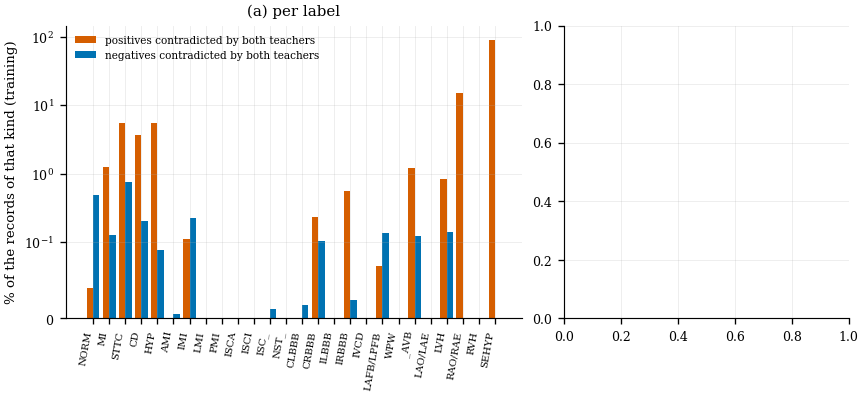

In [19]:
# Fig. S7-14  teacher-label conflicts
CT = CONFL[CONFL.split == 'train'].set_index('label')
fig, axes = plt.subplots(1, 2, figsize=(W2, 3.3), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axes[0]
xx = np.arange(26)
ax.bar(xx - 0.2, CT.loc[LABELS, 'frac_pos'] * 100, 0.4, color='#D55E00', label='positives contradicted by both teachers')
ax.bar(xx + 0.2, CT.loc[LABELS, 'frac_neg'] * 100, 0.4, color='#0072B2', label='negatives contradicted by both teachers')
ax.set_yscale('symlog', linthresh=0.1); ax.set_xticks(xx); ax.set_xticklabels(LABELS, rotation=80, ha='right', fontsize=6)
ax.set_ylabel('% of the records of that kind (training)'); ax.legend(fontsize=6.3); ax.set_title('(a) per label')
ax = axes[1]
cnt = np.bincount(c_tr, minlength=8)
ax.bar(range(len(cnt)), cnt, color='#777777'); ax.set_yscale('log'); ax.set_xlabel('conflicting labels in one record'); ax.set_ylabel('training records'); ax.set_title('(b) per record')
fig.suptitle(f'Fig. S7-14  Where the teachers and the labels disagree (prior-corrected probability below {S7["conflict_lo"]} or above {S7["conflict_hi"]}); a diagnostic, not applied', fontsize=8.5)
save_fig(fig, 'figS7_14_label_conflicts')

# Fig. S7-15  reading speed of the cache
fig, axes = plt.subplots(1, 2, figsize=(W2, 2.8))
names_b = list(BENCH)
bp = axes[0].boxplot([BENCH[k] for k in names_b], vert=False, patch_artist=True, showfliers=False)
for p_, c in zip(bp['boxes'], ['#BBBBBB', '#56B4E9', '#0072B2']):
    p_.set_facecolor(c)
axes[0].set_yticklabels(['RAM,\nall keys', 'cache_lib,\nall keys', 'cache_lib,\nStage-8 keys\nto the GPU'], fontsize=6.5); axes[0].set_xlabel(f'milliseconds per batch of {S7["bench_bs"]}'); axes[0].set_title('(a) latency')
axes[1].bar(range(3), BENCH_DF.batches_per_s, color=['#BBBBBB', '#56B4E9', '#0072B2'])
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(['RAM', 'cache_lib', 'cache_lib\n-> GPU'], fontsize=6.5); axes[1].set_ylabel('batches per second'); axes[1].set_title('(b) throughput')
for i, v in enumerate(BENCH_DF.batches_per_s):
    axes[1].text(i, v * 1.01, f'{v:.0f}', ha='center', fontsize=6.5)
fig.suptitle(f'Fig. S7-15  Reading random batches from the cache ({N_TR // S7["bench_bs"]} batches make one Stage-8 epoch)', fontsize=9)
save_fig(fig, 'figS7_15_read_speed')

# Fig. S7-16  checklist
AU = pd.DataFrame(AUDIT)
h = 0.75 + 0.19 * len(AU)
fig, ax = plt.subplots(figsize=(W2, h))
ax.set_xlim(0, 1); ax.set_ylim(0, len(AU) + 1); ax.axis('off'); ax.grid(False)
ax.text(0.0, len(AU) + 0.35, 'check', fontsize=7, fontweight='bold'); ax.text(0.80, len(AU) + 0.35, 'value', fontsize=7, fontweight='bold', ha='right'); ax.text(0.90, len(AU) + 0.35, 'tolerance', fontsize=7, fontweight='bold', ha='right')
ax.text(1.0, len(AU) + 0.35, 'result', fontsize=7, fontweight='bold', ha='right')
for i, r_ in AU.iterrows():
    y = len(AU) - 1 - i
    ax.text(0.0, y + 0.4, r_.check[:112], fontsize=5.9, va='center')
    ax.text(0.80, y + 0.4, f'{r_.value:.4g}', fontsize=5.9, va='center', ha='right', family='monospace')
    ax.text(0.90, y + 0.4, '-' if not np.isfinite(r_.tolerance) else f'{r_.tolerance:g}', fontsize=5.9, va='center', ha='right', family='monospace')
    ax.text(1.0, y + 0.4, 'PASS' if r_.passed else 'FAIL', fontsize=6.2, va='center', ha='right', fontweight='bold', color='#009E73' if r_.passed else '#D55E00')
    ax.axhline(y, color='#DDDDDD', lw=0.4)
ax.set_title(f'Fig. S7-16  Audit of the frozen teachers and of the cache: {int(AU.passed.sum())} of {len(AU)} checks passed', loc='left', fontsize=9)
save_fig(fig, 'figS7_16_audit_checklist')
FIG_DF = pd.DataFrame(FIGLOG)
FIG_DF.to_csv(os.path.join(TAB_DIR, 'figures_index.csv'), index=False)
print(FIG_DF.to_string(index=False))

## 12. Summary and what Stage 8 should take from it


In [20]:
need('CEIL', 'GAP', 'AGR', 'FIGLOG', 'BENCH_DF')
BEST_BLEND = CEIL.macro_auc.idxmax()
cm = CEIL.loc['Professor']
dn = CEIL.loc['DEAN']
overlap = (cm.lo <= dn.hi) and (dn.lo <= cm.hi)
STAGE8 = {
    'in_sample_gap_professors': float(rel.prof_gap.mean()), 'in_sample_gap_dean_oof': float(rel.dean_oof_gap.mean()),
    'ceiling_best_point_estimate': BEST_BLEND, 'ceiling_table': CEIL[['macro_auc', 'lo', 'hi']].round(4).to_dict(orient='index'),
    'professor_vs_dean_intervals_overlap': bool(overlap),
    'gate_val_top1': GM_va['top1'], 'gate_oof_top1': GM_tr_oof['top1'], 'gate_in_sample_top1': GM_tr_in['top1'],
    'teacher_label_conflict_records_train': float((c_tr > 0).mean()),
    'mean_spearman_prof_hod_val': float(AGR.prof_hod_val.mean()), 'mean_spearman_prof_dean_val': float(AGR.prof_dean_val.mean()),
}
print('=' * 74)
print('STAGE 7 SUMMARY')
print('=' * 74)
print(f"cache: {len(FILES)} arrays, {INV_DF.MB.sum() / 1e3:.2f} GB, {len(problems)} integrity problems | audits passed: {sum(a['passed'] for a in AUDIT)} of {len(AUDIT)}")
print(f"training records {N_TR}, validation records {N_VA}, fold 10 not read")
print(f"gate: {GATE_PARAMS:,} parameters, validation top-1 routing {GM_va['top1']:.3f}, out-of-fold {GM_tr_oof['top1']:.3f}, in-sample {GM_tr_in['top1']:.3f}")
print(f"in-sample gap (training AUC minus validation AUC, reliable subclasses): Professors {rel.prof_gap.mean():.3f}, DEAN out-of-fold {rel.dean_oof_gap.mean():.3f}")
print('ceiling of the targets (validation macro-AUC):', {k: round(float(v), 4) for k, v in CEIL.macro_auc.items()})
print(f"Professor and DEAN intervals overlap: {overlap}")
print('\nWhat this means for Stage 8')
print(' 1. The Professor and HOD training logits are in-sample (training AUC close to 1); use the out-of-fold DEAN logits in the target, and run the target source as an ablation.')
print(' 2. The out-of-fold gate is the honest g(x); the in-sample one is what a literal reading caches. Both are available.')
print(' 3. Differences between the blends are small against the intervals above: any claim that one blend is better needs the Stage-8 ablation, not this table.')
print(' 4. The conflict flags are a diagnostic only. A Chief Resident that down-weights them is an additional, separately reported experiment.')
json.dump(dict(version=CACHE_VERSION, audit=AUDIT, stage8=STAGE8, figures=FIGLOG, gate=dict(params=GATE_PARAMS, best_epoch=GATE_BEST, val=GM_va, oof=GM_tr_oof, insample=GM_tr_in),
               benchmark=BENCH_DF.round(3).to_dict(orient='index'), run_time_h=(time.time() - NB_T0) / 3600),
          open(os.path.join(WORK, 'stage7_report.json'), 'w'), indent=1, default=float)
print(f'\ntotal notebook time {(time.time() - NB_T0) / 3600:.2f} h')
print('files in /kaggle/working:')
for root, _, files in os.walk(WORK):
    for f in sorted(files):
        p = os.path.join(root, f)
        if '__pycache__' in p or p.endswith('.ipynb'):
            continue
        print(f'  {os.path.relpath(p, WORK):62s} {os.path.getsize(p) / 1e6:9.2f} MB')

STAGE 7 SUMMARY
cache: 28 arrays, 0.65 GB, 0 integrity problems | audits passed: 24 of 24
training records 17418, validation records 2183, fold 10 not read
gate: 264,197 parameters, validation top-1 routing 0.834, out-of-fold 0.895, in-sample 0.900
in-sample gap (training AUC minus validation AUC, reliable subclasses): Professors 0.064, DEAN out-of-fold -0.001
ceiling of the targets (validation macro-AUC): {'Professor': 0.9339, 'HOD': 0.9333, 'DEAN': 0.9298, 'mean(Professor, DEAN)': 0.9363, 'mean(Professor, HOD)': 0.9363, 'mean(Professor, HOD, DEAN)': 0.9377}
Professor and DEAN intervals overlap: True

What this means for Stage 8
 1. The Professor and HOD training logits are in-sample (training AUC close to 1); use the out-of-fold DEAN logits in the target, and run the target source as an ablation.
 2. The out-of-fold gate is the honest g(x); the in-sample one is what a literal reading caches. Both are available.
 3. Differences between the blends are small against the intervals above:

## 13. After this notebook
1. Save a version (Save & Run All) and publish `/kaggle/working` as the Dataset **`teacher-cache-v1`**. Stage 8 needs `teacher_cache/` (all of it), nothing else from here. Keep `tables/` and `figures/` for the report.
2. In Stage 8, read the cache with `cache_lib.TeacherCache`; do not re-implement the loader. `manifest.json` lists the order of the labels, which arrays are in-sample, and the checksums.
3. **Read before designing the Chief Resident:** `insample_gap.csv` and Fig. S7-9 (how sharp the Professor targets are on the training records), `target_ceiling.csv` and Fig. S7-11 (what each blend of targets could at best give), and `teacher_label_conflicts.csv`.
4. The three controls that make the central claim testable belong to Stage 8: the same Chief Resident distilled from (a) DEAN alone, (b) the HODs, (c) the full Professor cascade. The cache already holds the targets for all three.
5. Fold 10 is untouched. Stage 10 evaluates on it once.
